![Banner](../images/09_09_banner_rs_image_classification.png)


# Spatio-Temporal and Multi-Sensor Crop Mapping: Sentinel-2, Sentinel-1 and Landsat Time Series, 2020 to 2025

A crop is defined by its **season**, not by one image.


## Overview

In the US Corn Belt, corn and soybeans look alike in June and again after harvest; they differ in *when* they green up, how fast the canopy closes, how long it stays green and when it senesces. This notebook moves from single-date classification (earlier notebooks) to **satellite image time series**, using six seasons (2020 to 2025) of three sensors over the same AOI in north-central Iowa (`Corn_belt/aoi.geojson`):

- **Sentinel-2** L2A, 34 dates (one clear image per month, May-October), 10 spectral bands;
- **Sentinel-1** RTC, 33 dates (VV, VH), unaffected by clouds;
- **Landsat 8/9** L2, 18 dates at 30 m, used for the resolution experiment;
- **USDA Cropland Data Layer** (CDL) of every year as labels, and the USDA **2025 cultivated layer**.

We follow one question through eight steps, all with `geolattice.rsense.classify.image_classification` (`ic`):

1. **Building a pixel time series** with `pixel_time_series`: cloud masks, irregular dates, temporal interpolation.
2. **Leakage across time** with `temporal_split`: train on 2020 to 2023, test on the unseen seasons 2024 to 2025.
3. **A classical baseline**: Random Forest on phenology features.
4. **Temporal deep models** with `build_temporal_model`: TempCNN, LSTM and L-TAE for pixels, PSE-TAE for parcels, ConvLSTM and U-TAE for image patches.
5. **Optical-SAR fusion**: `fuse_early`, `build_fusion_model` (middle) and `fuse_late`, and which one wins under cloud.
6. **Gap filling** with `sar_assisted_gap_fill`, keeping a reconstruction flag so filled pixels are never treated as observed.
7. **Resolution** with `pansharpen` and `pansharpening_quality` (Wald protocol: degrade, sharpen, compare).
8. **In-season mapping**: accuracy against the last date available.

A GPU is recommended; on a CPU, reduce `EPOCHS` in the setup cell. The full notebook runs in about 30 minutes on one RTX A5500 (the first run also builds a 2.5 GB cache of the 20 m cubes).


## Core concepts

### Learning objectives

1. Turn a folder of dated rasters into a `(time, band, y, x)` cube and into `(N, T, C)` pixel series with `pixel_time_series`, handling clouds and irregular dates explicitly.
2. Explain why a random split of pixel-years leaks information across seasons, and evaluate on unseen years with `temporal_split`.
3. Derive phenology metrics (start, peak and end of season, amplitude, integral) and use them in a Random Forest.
4. Explain the mathematics of TempCNN, LSTM, the lightweight temporal attention encoder (L-TAE), the pixel-set encoder (PSE-TAE), ConvLSTM and U-TAE, and train them with `train_model`.
5. Compare early, middle and late optical-SAR fusion, and design a model that degrades gracefully when optical data are lost to cloud.
6. Fill optical gaps from SAR, measure the reconstruction error under the gap, and keep reconstructed values out of validation.
7. Validate pansharpening at reduced resolution (Wald protocol) with ERGAS, SAM, RMSE and correlation.
8. Measure how early in the season a crop map becomes reliable, without letting future images leak into the past.

### Contents

1. Setup: libraries, device and data paths
2. The data: three sensors, six seasons, labels
3. Building a pixel time series: `pixel_time_series`, cloud masks, irregular dates, temporal interpolation
4. Leakage across time: `temporal_split`
5. Classical baseline: Random Forest on phenology features
6. Temporal deep models: pixels (TempCNN, LSTM, L-TAE), parcels (PSE-TAE), patches (ConvLSTM, U-TAE)
7. Optical-SAR fusion: early, middle and late, and which wins under cloud
8. Gap filling: `sar_assisted_gap_fill` with a reconstruction flag
9. Resolution: `pansharpen` and `pansharpening_quality` (Wald protocol)
10. In-season mapping: accuracy against the last date available
11. Wall-to-wall 2025 map
12. Summary of the experiments
13. Interpretation, caveats and recommended recipe


### Task and evaluation design

**Task.** Pixel-wise (and parcel- or patch-wise) classification of the **growing season** into six classes recoded from the CDL: corn, soybeans, grass/pasture, developed, wetland/forest and other. One sample is one pixel in one year: its May-October series of 10 optical bands (and 2 SAR bands), labelled with that year's CDL class.

**Grid.** All rasters are put on one **20 m grid** (UTM 15N, 1516 × 1456 px): the Sentinel-2 10 m bands and Sentinel-1 are averaged onto it, the 20 m bands are native, labels are taken by nearest neighbour. Pansharpening (see *Resolution: `pansharpen` and `pansharpening_quality` (Wald protocol)*) uses the native 10 m and 30 m data.

**Splits.** *Temporal*: train 2020 to 2022, model selection on 2023, test 2024 to 2025 (`temporal_split`). The *Leakage across time: `temporal_split`* section shows why random splits are optimistic. The same 40 000 locations are sampled every year.

**Caveat.** The CDL is itself a classification (about 95 % accurate for corn and soybeans in Iowa, lower for minor classes), so scores measure agreement with CDL.


## Setup: libraries, device and data paths

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json, time, warnings  # JSON, timing and warning control
from pathlib import Path  # file paths
warnings.filterwarnings("ignore")  # hide library warnings
import numpy as np, pandas as pd, xarray as xr, rioxarray  # arrays, tables, labelled rasters and raster I/O
import geopandas as gpd  # vector data (sample points)
import matplotlib.pyplot as plt  # figures
import matplotlib.dates as mdates  # date axes
from matplotlib.colors import ListedColormap  # class colours
from scipy import ndimage as ndi  # image morphology and labelling
import torch  # PyTorch: the temporal networks
import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module
from geolattice.rsense.timeseries.phenology import phenology  # GeoLattice phenology metrics

CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_09_image_classification/Corn_belt"),  # the data folder, from the notebook folder or the repository root
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)  # the first candidate that exists
if DATA is None:  # neither found
    # stop with a clear message
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")
# Sentinel-2, Sentinel-1 and Landsat folders
S2_DIR, S1_DIR, L8_DIR = DATA / "Sentinel_2", DATA / "Sentinel_1", DATA / "Landsat_9"
# CDL folder and the 2025 cultivated layer
CDL_DIR, CULT = DATA / "CDL" / "30_m", DATA / "2025_cultivated_layer" / "2025_cultivated_layer.tif"
CACHE = DATA / "cache_20m"  # cache of the 20 m cubes
OUT = DATA / "outputs" / "spatio_temporal"  # output folder
for p in (CACHE, OUT):  # both folders ...
    p.mkdir(parents=True, exist_ok=True)  # ... are created if needed

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
print("torch", torch.__version__, "| device:", DEVICE,  # PyTorch version and device
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only (reduce EPOCHS below)")
SEED = 42  # random seed
ic.set_seed(SEED)  # reproducible numpy and PyTorch randomness
rng = np.random.default_rng(SEED)  # random generator
EPOCHS = 30 if DEVICE == "cuda" else 8  # training epochs (fewer on a CPU)
YEARS = list(range(2020, 2026))  # the six seasons


torch 2.14.0+cu132 | device: cuda | NVIDIA RTX A5500 Laptop GPU


## The data: three sensors, six seasons, labels

Each sensor folder holds one sub-folder per acquisition (`<year>_<month>_<yyyymmdd>`). The download scripts kept at most one image per month from May to October; for the optical sensors only images with at least 90 % of the AOI clear were kept, so some months are missing.


year         2020  2021  2022  2023  2024  2025
sensor                                         
Landsat 8/9     2     2     3     6     2     3
Sentinel-1      6     6     5     5     5     6
Sentinel-2      5     6     5     6     6     6
Sentinel-1 relative orbits (dates): {'63': 31, '165': 2}


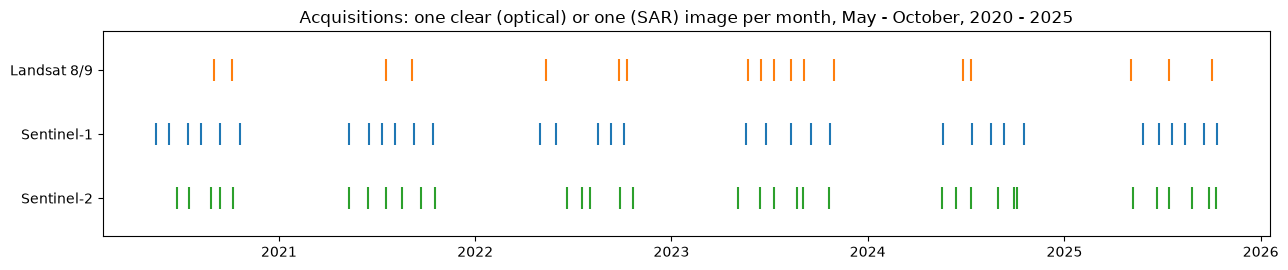

In [2]:
def folders(d, n):  # dated sub-folders, sorted by date
    # dated sub-folders: <year>_<month>_<yyyymmdd>[_...]
    return sorted([p for p in d.iterdir() if p.is_dir() and p.name[:4].isdigit()], key=lambda p: p.name.split("_")[n])

def folder_date(p, n):  # date encoded in a folder name
    return pd.Timestamp(p.name.split("_")[n])  # the n-th part of the name

S2_F = folders(S2_DIR, 2); S1_F = folders(S1_DIR, 2); L8_F = folders(L8_DIR, 5)  # folders of the three sensors
inv = pd.concat([pd.DataFrame({"sensor": s, "date": [folder_date(p, n) for p in fl]})  # one row per acquisition
                 for s, fl, n in [("Sentinel-2", S2_F, 2), ("Sentinel-1", S1_F, 2), ("Landsat 8/9", L8_F, 5)]])
inv["year"], inv["month"] = inv.date.dt.year, inv.date.dt.month  # year and month columns
print(inv.groupby(["sensor", "year"]).size().unstack(fill_value=0))  # acquisitions per sensor and year
# Sentinel-1 relative orbits used
s1_orbits = pd.Series([p.name.split("_")[3] for p in S1_F]).value_counts().to_dict()
print("Sentinel-1 relative orbits (dates):", s1_orbits)  # report them

fig, ax = plt.subplots(figsize=(13, 2.8))  # one panel
# each sensor
for i, (s, c) in enumerate([("Sentinel-2", "tab:green"), ("Sentinel-1", "tab:blue"), ("Landsat 8/9", "tab:orange")]):
    d = inv[inv.sensor == s].date  # its dates
    ax.scatter(d, np.full(len(d), i), marker="|", s=250, color=c)  # one tick per acquisition
# sensor names and limits
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["Sentinel-2", "Sentinel-1", "Landsat 8/9"]); ax.set_ylim(-0.6, 2.6)
# title
ax.set_title("Acquisitions: one clear (optical) or one (SAR) image per month, May - October, 2020 - 2025")
plt.tight_layout(); plt.show()  # arrange and draw

**What the inventory shows.** Sentinel-2 has 5 to 6 dates per season (no clear May image in 2020 and 2022). Sentinel-1 has 5 to 6 per season, almost all on relative orbit 63 (two dates come from orbit 165). Landsat is sparse (2 to 6 per season) because of its 16-day revisit and clouds; it is used only for the resolution experiment in the *Resolution: `pansharpen` and `pansharpening_quality` (Wald protocol)* section.

### Cubes on the 20 m grid

For each Sentinel-2 date we read the 10 bands, average the 10 m bands to 20 m, convert DN to reflectance (×10⁻⁴; the boundary offset was already removed at download) and mask clouds, cirrus, shadows, snow and no data with the scene classification layer (SCL). Sentinel-1 γ⁰ is averaged to 20 m (which also reduces speckle) and converted to dB. The CDL of each year and the national 2025 cultivated layer are clipped and resampled by nearest neighbour. The cubes are cached as NetCDF in `Corn_belt/cache_20m` (built once, in about 2 minutes).


In [3]:
# the ten Sentinel-2 bands
BANDS = ["blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # the six classes
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]
# CDL code -> class id
CODE_MAP = {1: 0, 5: 1, 176: 2, 121: 3, 122: 3, 123: 3, 124: 3, 190: 4, 195: 4, 141: 4, 142: 4, 143: 4}
K = len(CLASSES)  # number of classes
cmap = ListedColormap(COLORS)  # their colour map
# the 20 m grid of the Sentinel-2 SWIR bands; 10 m bands and SAR are averaged onto it, labels taken by nearest neighbour
REF = rioxarray.open_rasterio(S2_F[0] / "swir16.tif").squeeze(drop=True)

def to_grid(path, resampling):  # a raster on the 20 m grid
    a = rioxarray.open_rasterio(path, masked=True).squeeze(drop=True)  # read it with no-data masked
    # resample only when the grid differs
    return a if a.shape == REF.shape and np.allclose(a.x, REF.x) else a.rio.reproject_match(REF, resampling=resampling)

def build_s2():  # Sentinel-2 cube (time, band, y, x), cached
    f = CACHE / "s2_20m.nc"  # cache file
    if f.exists():  # cached already
        return xr.open_dataarray(f).load()  # load it
    out = []  # one array per date
    for p in S2_F:  # every scene
        scl = to_grid(p / "scl.tif", 0).values  # scene classification on the 20 m grid
        bad = np.isin(scl, [0, 1, 3, 8, 9, 10, 11]) | ~np.isfinite(scl)        # no data, saturated, shadow, cloud, cirrus, snow
        layers = [to_grid(p / f"{b}.tif", 5).values.astype("float32") * 1e-4 for b in BANDS]   # 5 = average
        # drop flagged and non-positive values
        a = np.where(bad[None] | ~(np.stack(layers) > 0), np.nan, np.stack(layers))
        out.append(a.astype("float32"))  # keep the date
    da = xr.DataArray(np.stack(out), dims=("time", "band", "y", "x"),  # as a labelled cube
                      coords={"time": [folder_date(p, 2) for p in S2_F], "band": BANDS, "y": REF.y, "x": REF.x}, name="s2")
    da.to_netcdf(f, encoding={"s2": {"zlib": True, "complevel": 3}})  # save to the cache
    return da  # the cube

def build_s1():  # Sentinel-1 cube (time, VV/VH, y, x) in dB, cached
    f = CACHE / "s1_20m.nc"  # cache file
    if f.exists():  # cached already
        return xr.open_dataarray(f).load()  # load it
    # VV and VH of every scene on the 20 m grid
    out = [np.stack([to_grid(p / f"{b}.tif", 5).values.astype("float32") for b in ("vv", "vh")]) for p in S1_F]
    lin = np.stack(out)  # linear power
    # in dB, non-positive values as missing
    db = np.where(lin > 0, 10 * np.log10(np.where(lin > 0, lin, 1)), np.nan).astype("float32")
    da = xr.DataArray(db, dims=("time", "band", "y", "x"),  # as a labelled cube
                      coords={"time": [folder_date(p, 2) for p in S1_F], "band": ["vv", "vh"], "y": REF.y, "x": REF.x}, name="s1")
    da.to_netcdf(f, encoding={"s1": {"zlib": True, "complevel": 3}})  # save to the cache
    return da  # the cube

def recode(raw):  # CDL codes -> class ids
    lab = np.full(raw.shape, 5, "int16")  # everything else is "Other" (5)
    for k, v in CODE_MAP.items():  # the mapped codes ...
        lab[raw == k] = v  # ... get their class
    lab[(raw == 0) | ~np.isfinite(raw)] = -1  # no data
    return lab  # the class map

def build_labels():  # CDL of all six years and the cultivated layer, cached
    f = CACHE / "labels_20m.nc"  # cache file
    if f.exists():  # cached already
        return xr.open_dataset(f).load()  # load it
    # recoded CDL of every year on the 20 m grid
    cdl = np.stack([recode(to_grid(CDL_DIR / f"CDL_{y}_30m.tif", 0).values) for y in YEARS])
    big = rioxarray.open_rasterio(CULT, masked=True).squeeze(drop=True)  # the national cultivated layer
    b = REF.rio.transform_bounds("EPSG:5070")  # grid bounds in its CRS
    # clip and resample it to the grid
    cult = big.rio.clip_box(b[0] - 300, b[1] - 300, b[2] + 300, b[3] + 300).rio.reproject_match(REF, resampling=0).values
    # both as one Dataset
    ds = xr.Dataset({"cdl": (("year", "y", "x"), cdl), "cultivated": (("y", "x"), np.nan_to_num(cult).astype("uint8"))},
                    coords={"year": YEARS, "y": REF.y, "x": REF.x})
    ds.to_netcdf(f)  # save to the cache
    return ds  # the labels

t0 = time.time()  # start the timer
S2C, S1C, LAB = build_s2(), build_s1(), build_labels()  # build or load the three cubes
for da in (S2C, S1C):  # both image cubes ...
    da.rio.write_crs(REF.rio.crs, inplace=True)  # ... get the CRS
# time and grid
print(f"cubes ready in {time.time() - t0:.0f} s | grid {REF.shape[1]} x {REF.shape[0]} px at 20 m, CRS {REF.rio.crs}")
# cube shapes and memory
print(f"Sentinel-2 {tuple(S2C.shape)} (time, band, y, x), {S2C.nbytes / 1e9:.1f} GB | Sentinel-1 {tuple(S1C.shape)}")
# masked share of every Sentinel-2 date
cloud = pd.Series(np.isnan(S2C.isel(band=0).values).mean((1, 2)), index=pd.DatetimeIndex(S2C.time.values))
# median and worst date
print(f"masked Sentinel-2 pixels per date: median {cloud.median():.2%}, max {cloud.max():.2%} ({cloud.idxmax().date()})")
# values of the cultivated layer
print("cultivated layer values:", dict(zip(*np.unique(LAB.cultivated.values, return_counts=True))))

cubes ready in 13 s | grid 1516 x 1456 px at 20 m, CRS EPSG:32615
Sentinel-2 (34, 10, 1456, 1516) (time, band, y, x), 3.0 GB | Sentinel-1 (33, 2, 1456, 1516)
masked Sentinel-2 pixels per date: median 0.00%, max 4.38% (2024-07-12)
cultivated layer values: {np.uint8(1): np.int64(197924), np.uint8(2): np.int64(2009372)}


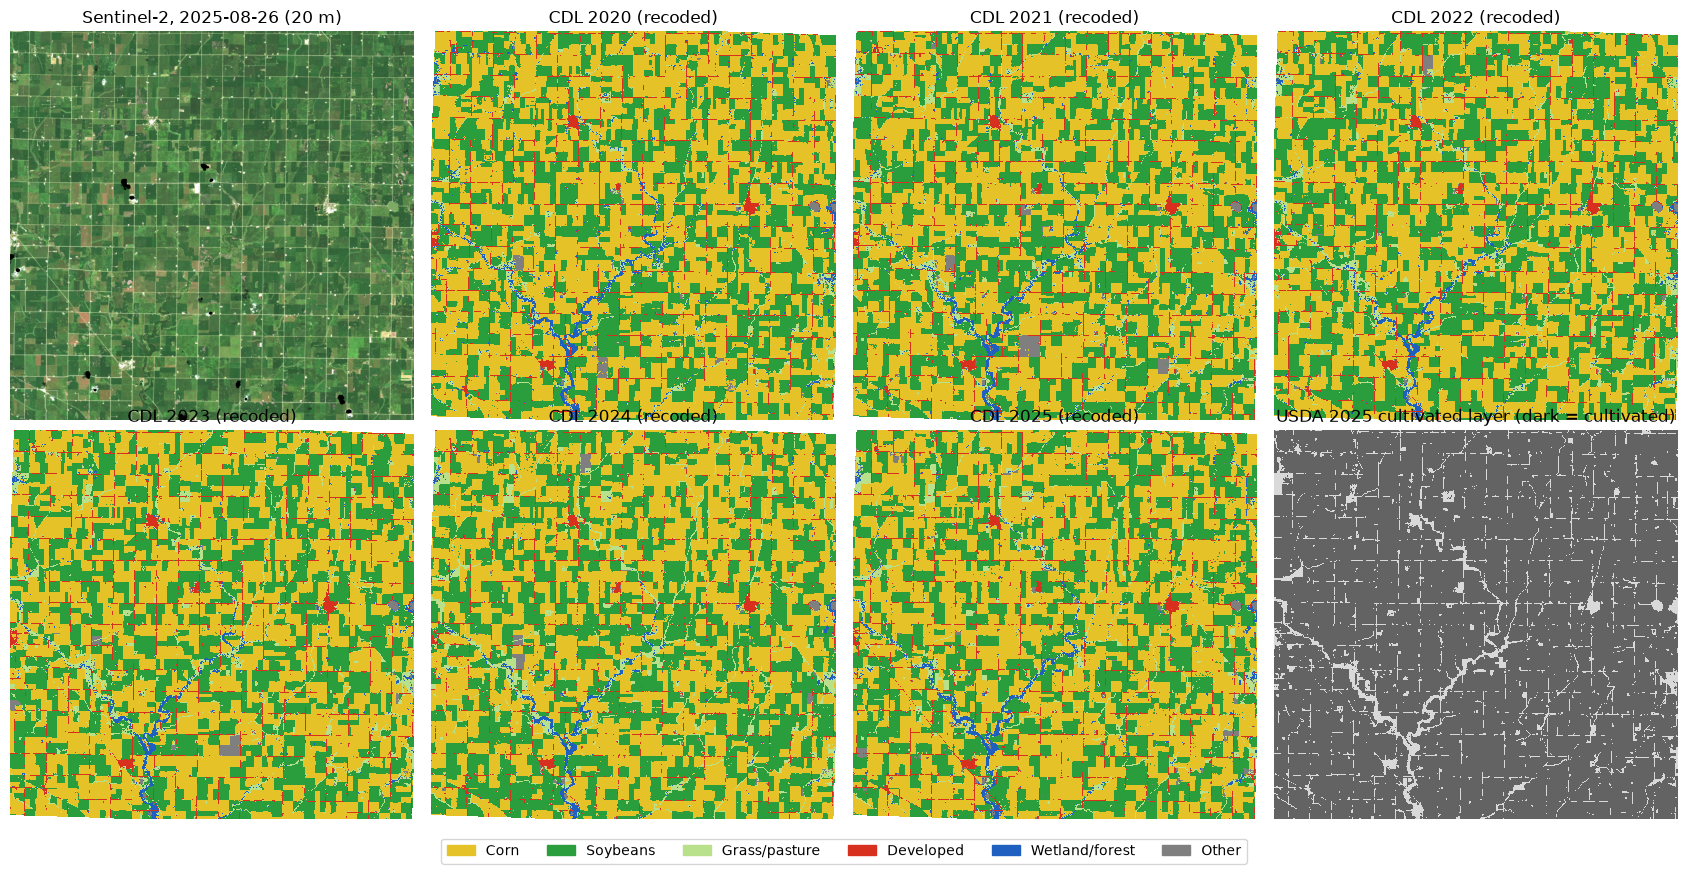

Class share per year (% of labelled pixels):
                2020  2021  2022  2023  2024  2025
Corn            53.7  51.0  49.1  50.4  48.9  52.6
Soybeans        36.3  38.1  40.1  38.6  41.0  36.4
Grass/pasture    2.9   3.9   4.4   4.7   4.9   3.9
Developed        4.2   4.4   4.4   4.4   3.5   4.5
Wetland/forest   2.1   1.5   1.3   1.2   1.0   1.5
Other            0.8   1.0   0.5   0.7   0.7   1.0

corn/soy pixels that switch crop from one year to the next: 86 %
share of each 2025 CDL class on land the cultivated layer marks as cultivated: {'Corn': np.float64(99.1), 'Soybeans': np.float64(99.1), 'Grass/pasture': np.float64(25.8), 'Developed': np.float64(24.7), 'Wetland/forest': np.float64(11.6), 'Other': np.float64(55.8)}


In [4]:
def rgb(a, lo=0.0, hi=0.12):  # true colour of one date
    im = np.moveaxis(a.sel(band=["red", "green", "blue"]).values, 0, -1)  # red, green, blue with bands last
    return np.clip((np.nan_to_num(im) - lo) / (hi - lo), 0, 1) ** 0.8  # stretch, clip and brighten slightly

cdl = LAB.cdl.values  # CDL of every year
fig, ax = plt.subplots(2, 4, figsize=(17, 8.6))  # two rows of four panels
ax = ax.ravel()  # as a flat list
# one Sentinel-2 date
ax[0].imshow(rgb(S2C.sel(time="2025-08-26").squeeze())); ax[0].set_title("Sentinel-2, 2025-08-26 (20 m)")
for i, y in enumerate(YEARS):  # each year ...
    # ... its CDL
    ax[i + 1].imshow(np.where(cdl[i] < 0, np.nan, cdl[i]), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")
    ax[i + 1].set_title(f"CDL {y} (recoded)")  # title
ax[7].imshow(LAB.cultivated.values, cmap=ListedColormap(["white", "#d9d9d9", "#636363"]), vmin=-0.5, vmax=2.5, interpolation="nearest")
ax[7].set_title("USDA 2025 cultivated layer (dark = cultivated)")  # title
for a in ax:  # every panel
    a.axis("off")  # no axes
# class legend
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()  # arrange and draw

# class shares per year
share = pd.DataFrame({y: pd.Series(cdl[i][cdl[i] >= 0]).value_counts(normalize=True).reindex(range(K)).fillna(0).values * 100
                      for i, y in enumerate(YEARS)}, index=CLASSES).round(1)
print("Class share per year (% of labelled pixels):"); print(share)  # header and table
crop = np.isin(cdl, [0, 1])  # corn or soybean pixels
rot = (cdl[1:] != cdl[:-1]) & crop[1:] & crop[:-1]  # pixels that switch between corn and soybeans
# rotation rate
print(f"\ncorn/soy pixels that switch crop from one year to the next: {rot.sum() / (crop[1:] & crop[:-1]).sum() * 100:.0f} %")
cult = LAB.cultivated.values == 2  # cultivated pixels
# share of each 2025 class that is cultivated
print("share of each 2025 CDL class on land the cultivated layer marks as cultivated:",
      {CLASSES[k]: round(cult[cdl[-1] == k].mean() * 100, 1) for k in range(K)})

**Reading the labels.** Corn (49 to 54 %) and soybeans (36 to 41 %) cover about 90 % of the AOI every year, and **86 % of the corn and soybean pixels switch crop from one year to the next**: the corn-soybean rotation. A map of last year's crop is therefore almost a map of this year's *other* crop. This is why a crop map must be judged on seasons it has not seen (see *Leakage across time: `temporal_split`*). The **2025 cultivated layer** marks 99 % of the corn and soybean pixels as cultivated and only a quarter of the grass and developed pixels; we use it in the *Wall-to-wall 2025 map* section to score the map on cropland.


## Building a pixel time series: `pixel_time_series`, cloud masks, irregular dates, temporal interpolation

`pixel_time_series(cube, samples)` samples a `(time, band, y, x)` cube at point geometries (reprojected to the cube CRS, nearest pixel) and returns `X` of shape `(N, T, C)` with the dates. We draw **40 000 random locations** that are labelled in all six years and use the same locations every year, plus 2 km spatial blocks for the *Leakage across time: `temporal_split`* section.


In [5]:
# 40 000 random pixel locations with a label in every year; the same locations are used in all six years
labelled = (cdl >= 0).all(0)
N_LOC = 40_000  # number of sample locations
# random rows and columns
rr, cc = np.unravel_index(rng.choice(np.flatnonzero(labelled.ravel()), N_LOC, replace=False), labelled.shape)
# as points in the grid CRS
pts = gpd.GeoDataFrame({"row": rr, "col": cc}, geometry=gpd.points_from_xy(REF.x.values[cc], REF.y.values[rr]), crs=REF.rio.crs)

t0 = time.time()  # start the timer
X_s2, _, d_s2 = ic.pixel_time_series(S2C, pts)       # (N, 34, 10)
X_s1, _, d_s1 = ic.pixel_time_series(S1C, pts)       # (N, 33, 2)
# shapes and time
print(f"pixel_time_series: Sentinel-2 {X_s2.shape}, Sentinel-1 {X_s1.shape} in {time.time() - t0:.0f} s")
d_s2, d_s1 = pd.DatetimeIndex(d_s2), pd.DatetimeIndex(d_s1)  # dates as DatetimeIndex
# share of masked optical values
print(f"cloud-masked Sentinel-2 values in the samples: {np.isnan(X_s2[..., 0]).mean():.2%}")

# 2 km spatial blocks, used later for the spatio-temporal split
BLOCK = 2000
# 2 km block id of every location
blocks = ic.spatial_blocks(np.column_stack([pts.geometry.x, pts.geometry.y]), BLOCK)
print(f"{len(np.unique(blocks))} spatial blocks of {BLOCK / 1000:.0f} km")  # number of blocks

pixel_time_series: Sentinel-2 (40000, 34, 10), Sentinel-1 (40000, 33, 2) in 0 s
cloud-masked Sentinel-2 values in the samples: 0.16%
240 spatial blocks of 2 km


### Irregular dates and temporal interpolation

Each season has different acquisition days and sometimes a missing month, so the raw series are not comparable across years (the 3rd image of 2020 is 27 August, of 2021 20 July). Most models need a **common time axis**. We interpolate every pixel series onto six fixed days, the 15th of May to October ($d_1,\dots,d_6$ = day of year 135, 166, 196, 227, 258, 288). For a target day $d$ with the last valid observation before it at $t_a$ and the first after it at $t_b$,

$$
\hat x(d)=x(t_a)+\frac{d-t_a}{t_b-t_a}\,\big(x(t_b)-x(t_a)\big),
$$

and outside the observed range the nearest valid value is held. **Cloud-masked observations are skipped per pixel** (the interpolation bridges them), and for every target day we record the **gap**: the distance in days to the nearest valid observation. A value 40 days from any image is a guess, not a measurement.


interpolated 6 years x 40,000 pixels in 0 s
                                    Sentinel-2 dates nearest observation to the 6 target days (median days)
2020          25 Jun, 18 Jul, 27 Aug, 13 Sep, 08 Oct                                    42, 11, 4, 13, 1, 6
2021  11 May, 15 Jun, 20 Jul, 17 Aug, 23 Sep, 18 Oct                                       4, 0, 5, 2, 8, 3
2022          20 Jun, 18 Jul, 02 Aug, 28 Sep, 21 Oct                                    36, 5, 3, 13, 13, 6
2023  04 May, 15 Jun, 10 Jul, 22 Aug, 03 Sep, 21 Oct                                     11, 0, 5, 7, 12, 6
2024  18 May, 14 Jun, 12 Jul, 31 Aug, 30 Sep, 05 Oct                                     4, 0, 2, 17, 14, 9
2025  08 May, 22 Jun, 14 Jul, 26 Aug, 27 Sep, 10 Oct                                     7, 7, 1, 11, 12, 5


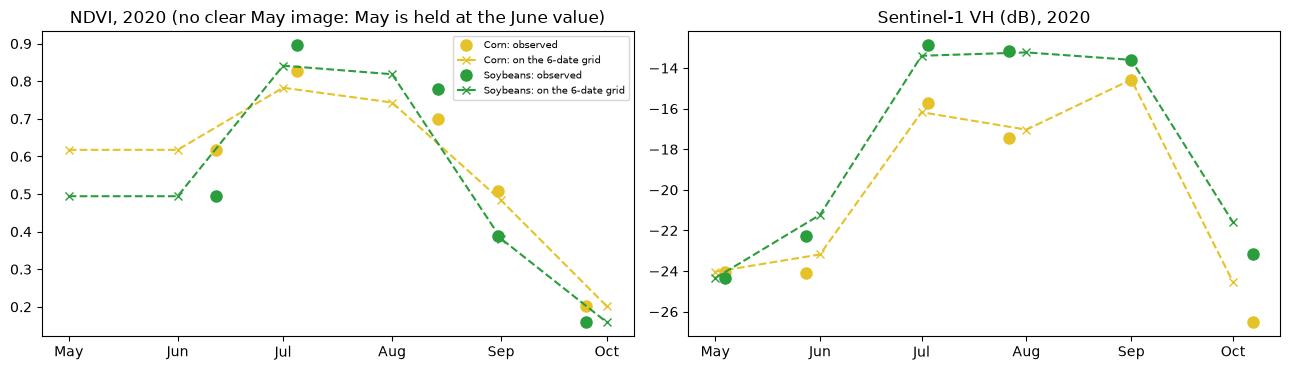

In [6]:
TGRID = np.array([135, 166, 196, 227, 258, 288])           # day of year: 15 May, 15 Jun, ..., 15 Oct
TLAB = ["May", "Jun", "Jul", "Aug", "Sep", "Oct"]  # month labels

def interp_series(X, doy, target=TGRID):  # interpolate irregular series onto fixed days
    """Linear interpolation of (N, T, C) series observed on irregular days `doy` onto `target` days.
    Masked (NaN) values are skipped per pixel and band: each target day is interpolated between the last
    valid observation before it and the first valid one after it; outside the observed range the nearest
    valid value is held (no extrapolation of trends). Returns the series (N, S, C) and the distance in
    days from each target day to the nearest valid observation of the pixel (N, S)."""
    X = np.asarray(X, "float32")  # as float32
    ok = np.isfinite(X)  # valid values
    out = np.empty((X.shape[0], len(target), X.shape[2]), "float32")  # output (N, 6, C)
    for s, d in enumerate(target):  # each target day
        # last valid value and its day
        pv = np.full((X.shape[0], X.shape[2]), np.nan, "float32"); pd_ = pv.copy()
        nv, nd_ = pv.copy(), pv.copy()  # first valid value and its day
        for t in range(len(doy)):                              # last valid observation on or before d
            if doy[t] <= d:  # a date on or before the target
                # update where valid
                pv = np.where(ok[:, t], X[:, t], pv); pd_ = np.where(ok[:, t], doy[t], pd_)
        for t in range(len(doy) - 1, -1, -1):                  # first valid observation on or after d
            if doy[t] >= d:  # a date on or after the target
                # update where valid
                nv = np.where(ok[:, t], X[:, t], nv); nd_ = np.where(ok[:, t], doy[t], nd_)
        w = np.where(nd_ > pd_, (d - pd_) / np.where(nd_ > pd_, nd_ - pd_, 1), 0)  # interpolation weight
        both = (1 - w) * np.nan_to_num(pv) + w * np.nan_to_num(nv)  # linear interpolation
        # interpolated, or the nearest valid value at the ends
        out[:, s] = np.where(np.isfinite(pv) & np.isfinite(nv), both, np.where(np.isfinite(pv), pv, nv))
    # distance of every date to every target day
    dist = np.abs(target[None, None, :] - np.asarray(doy)[None, :, None]).astype("float32")
    gap = np.where(ok.all(2)[:, :, None], dist, np.inf).min(1)  # distance to the nearest fully valid date
    return out, gap  # series and gaps

S2Y, S1Y, GAP = {}, {}, {}  # interpolated optical, SAR and gaps per year
t0 = time.time()  # start the timer
for y in YEARS:  # each year
    i2, i1 = np.flatnonzero(d_s2.year == y), np.flatnonzero(d_s1.year == y)  # its optical and SAR dates
    S2Y[y], GAP[y] = interp_series(X_s2[:, i2], d_s2[i2].dayofyear.values)  # optical series on the 6 days
    S1Y[y], _ = interp_series(X_s1[:, i1], d_s1[i1].dayofyear.values)  # SAR series on the 6 days
print(f"interpolated 6 years x {N_LOC:,} pixels in {time.time() - t0:.0f} s")  # time taken

# dates per year
obs = pd.DataFrame({y: [", ".join(f"{d:%d %b}" for d in d_s2[d_s2.year == y])] for y in YEARS}, index=["Sentinel-2 dates"]).T
# median gap to each target day
obs["nearest observation to the 6 target days (median days)"] = [", ".join(f"{v:.0f}" for v in np.median(GAP[y], 0)) for y in YEARS]
print(obs.to_string())  # show it

# one corn and one soybean pixel of 2020 (no May image): observed vs interpolated NDVI, and Sentinel-1 VH
ndvi = lambda a: (a[..., BANDS.index("nir")] - a[..., BANDS.index("red")]) / (a[..., BANDS.index("nir")] + a[..., BANDS.index("red")])
i2, i1 = np.flatnonzero(d_s2.year == 2020), np.flatnonzero(d_s1.year == 2020)  # the 2020 dates
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))  # two panels
for k, c in [(0, COLORS[0]), (1, COLORS[1])]:  # corn and soybeans
    j = np.flatnonzero(cdl[0][rr, cc] == k)[3]  # one example pixel of the class
    # observed NDVI
    ax[0].plot(d_s2[i2].dayofyear, ndvi(X_s2[j, i2]), "o", color=c, ms=8, label=f"{CLASSES[k]}: observed")
    # NDVI on the 6-day grid
    ax[0].plot(TGRID, ndvi(S2Y[2020][j]), "--x", color=c, label=f"{CLASSES[k]}: on the 6-date grid")
    # observed and interpolated VH
    ax[1].plot(d_s1[i1].dayofyear, X_s1[j, i1, 1], "o", color=c, ms=8); ax[1].plot(TGRID, S1Y[2020][j, :, 1], "--x", color=c)
# title and legend
ax[0].set_title("NDVI, 2020 (no clear May image: May is held at the June value)"); ax[0].legend(fontsize=7)
ax[1].set_title("Sentinel-1 VH (dB), 2020");   # title
for a in ax:  # both panels
    a.set_xticks(TGRID); a.set_xticklabels(TLAB)  # month ticks
plt.tight_layout(); plt.show()  # arrange and draw

**Reading the interpolation.** In 2020 and 2022 there is no clear May image, so the May value is the late-June value held constant, 36 to 42 days from the nearest image, while in other years May is within 4 to 11 days. The NDVI curves show the main crop signal: soybeans green up later but reach a higher peak, and senesce faster in September; corn is greener in June. In VH, soybeans are brighter than corn from July (a denser, more isotropic canopy for C-band). Interpolation preserves this shape between images, but cannot invent what happened in a 40-day gap.


## Leakage across time: `temporal_split`

`temporal_split(dates, train_end=, val_end=)` assigns samples by date: training up to `train_end`, validation up to `val_end`, test after it. Here the "date" of a sample is the end of its season, so train = 2020 to 2022, validation = 2023 (model selection and early stopping) and test = 2024 to 2025.

Why not a random split of pixel-years? Two kinds of information leak:

- **Season leakage.** Each season has its own weather, planting dates and atmosphere. With a random split, test pixels from 2024 are classified by a model that saw thousands of *other* 2024 pixels, so it has learned the 2024 timing. A real map of a new season never has that.
- **Location leakage.** The same field appears in several years and its neighbours in both sets. A spatio-temporal split also holds out 2 km blocks.

We train the same Random Forest (all 72 band values) three ways.


In [7]:
# one sample = one pixel in one year: (6 dates, 10 optical bands) + (6 dates, 2 SAR bands) + the CDL class of that year
X2 = np.concatenate([S2Y[y] for y in YEARS])                    # (240 000, 6, 10)
X1 = np.concatenate([S1Y[y] for y in YEARS])                    # (240 000, 6, 2)
G2 = np.concatenate([GAP[y] for y in YEARS])  # gaps of every sample
# CDL class of every pixel-year
Y = np.concatenate([cdl[i][rr, cc] for i, y in enumerate(YEARS)]).astype("int64")
YR = np.repeat(YEARS, N_LOC)  # year of every sample
LOC = np.tile(np.arange(N_LOC), len(YEARS))  # location of every sample
BLK = np.tile(blocks, len(YEARS))  # block of every sample
season_end = pd.to_datetime([f"{y}-12-31" for y in YR])  # end of each season

# train 2020-2022, validate 2023, test 2024-2025
sp = ic.temporal_split(season_end, train_end="2022-12-31", val_end="2023-12-31")
tr, va, te = sp.train, sp.val, sp.test  # the three index sets
# no year in two splits
ic.check_split_isolation(train=np.unique(YR[tr]), val=np.unique(YR[va]), test=np.unique(YR[te]))
# sizes and years
print({k: f"{len(v):,} samples, years {sorted(set(YR[v]))}" for k, v in [("train", tr), ("val", va), ("test", te)]})

def flat(*arrs):  # flatten and join feature arrays
    return np.concatenate([a.reshape(len(a), -1) for a in arrs], 1)  # one row per sample

{'train': '120,000 samples, years [np.int64(2020), np.int64(2021), np.int64(2022)]', 'val': '40,000 samples, years [np.int64(2023)]', 'test': '80,000 samples, years [np.int64(2024), np.int64(2025)]'}


In [8]:
from sklearn.ensemble import RandomForestClassifier  # random forest
def rf_fit_score(train_idx, test_idx, X):  # fit on one index set, score on another
    m = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED, min_samples_leaf=2)  # the forest
    sub = rng.choice(train_idx, min(60_000, len(train_idx)), replace=False)  # at most 60,000 training samples
    m.fit(X[sub], Y[sub])  # fit
    p = m.predict(X[test_idx])  # predict the test samples
    # report
    rep = ic.classification_report(Y[test_idx], p, labels=list(range(K)), class_names=dict(enumerate(CLASSES)))
    return rep["overall_accuracy"], rep["macro_f1"]  # accuracy and macro F1

XF = flat(X2, X1)  # optical and SAR features as one table
# (a) random split of pixel-years: the same field, the same season and its neighbours are on both sides
perm = rng.permutation(len(Y)); a_tr, a_te = perm[: int(0.7 * len(Y))], perm[int(0.7 * len(Y)):]
# (b) temporal split: train 2020-2023, test 2024-2025 (same locations, unseen seasons)
b_tr, b_te = np.r_[tr, va], te
# (c) spatio-temporal: test seasons AND test blocks; training uses only training seasons in training blocks
gs = ic.group_split(blocks, test_size=0.3, seed=SEED)
test_blocks = np.unique(blocks[gs.test])  # the test blocks
inb = np.isin(BLK, test_blocks)  # samples in test blocks
c_tr, c_te = np.r_[tr, va][~inb[np.r_[tr, va]]], te[inb[te]]  # training outside them, testing inside them
rows = {}  # one row per split
# the three splits
for name, (a, b) in {"(a) random pixel-year split": (a_tr, a_te), "(b) temporal split (2020-23 / 2024-25)": (b_tr, b_te),
                     "(c) spatio-temporal split (seasons and 2 km blocks)": (c_tr, c_te)}.items():
    oa, f1 = rf_fit_score(a, b, XF)  # fit and score
    rows[name] = {"train samples": len(a), "test samples": len(b), "OA": oa, "macro-F1": f1}  # store
leak = pd.DataFrame(rows).T  # as a table
leak[["OA", "macro-F1"]] = leak[["OA", "macro-F1"]].astype(float).round(3)  # round the scores
leak  # show it

,train samples,test samples,OA,macro-F1
(a) random pixel-year split,168000.0,72000.0,0.936,0.758
(b) temporal split (2020-23 / 2024-25),160000.0,80000.0,0.906,0.692
(c) spatio-temporal split (seasons and 2 km blocks),112676.0,23662.0,0.903,0.669


**Reading the leakage.** The random split reports OA 0.94 and macro-F1 0.76; testing on unseen seasons drops this to 0.91 and 0.69, and holding out space as well to 0.90 and 0.67. Most of the inflation comes from **sharing seasons**, not from sharing locations: a crop map must be evaluated on years it was not trained on. From here on every score is on the 2024 to 2025 test seasons.


## Classical baseline: Random Forest on phenology features

`geolattice.rsense.timeseries.phenology` extracts TIMESAT-style season metrics from a vegetation-index curve (Jönsson & Eklundh, 2004). With the left and right minima $b_L, b_R$, the peak $x_{\max}$ and the amplitude $A=x_{\max}-\tfrac12(b_L+b_R)$:

- **start / end of season** (SOS, EOS): the days where the curve crosses $b+0.2A$ before and after the peak;
- **peak of season** (POS): the day of $x_{\max}$; **length** LOS $=$ EOS $-$ SOS;
- **integral**: the area of the curve above its base between SOS and EOS; **green-up and senescence rates**: the slopes.

We add NDVI, NDMI (NIR vs SWIR-1, canopy water), NDRE (red edge) and NDWI (green vs NIR) of each month: 34 features. The **Random Forest** averages $B$ decision trees grown on bootstrap samples with random feature subsets, $\hat y=\operatorname{mode}\{h_b(\mathbf x)\}_{b=1}^{B}$, with balanced class weights.


In [9]:
def nd(a, b1, b2):  # normalised difference of two bands
    x, y = a[..., BANDS.index(b1)], a[..., BANDS.index(b2)]  # the two bands
    return (x - y) / (x + y + 1e-6)  # the index

NDVI = nd(X2, "nir", "red")                                    # (N, 6)
t0 = time.time()  # start the timer
# NDVI as a (time, sample) array
vi = xr.DataArray(NDVI.T, dims=("time", "s"), coords={"time": pd.to_datetime("2001-01-01") + pd.to_timedelta(TGRID - 1, "D")})
ph = phenology(vi, threshold=0.2, min_amplitude=0.1)            # TIMESAT-style season metrics per sample
print(f"phenology metrics for {len(Y):,} pixel-years in {time.time() - t0:.0f} s")  # time taken
# the ten phenology metrics
PH_KEYS = ["sos", "pos", "eos", "los", "peak", "base", "amplitude", "integral", "greenup_rate", "senescence_rate"]
PHEN = np.column_stack([ph[k].values for k in PH_KEYS]).astype("float32")  # as a (sample, metric) array
SPEC = np.column_stack([NDVI, nd(X2, "nir", "swir16"), nd(X2, "nir08", "rededge1"), nd(X2, "green", "nir")])   # NDVI, NDMI, NDRE, NDWI per month
# metric and index names
FEAT_NAMES = PH_KEYS + [f"{i}_{m}" for i in ("NDVI", "NDMI", "NDRE", "NDWI") for m in TLAB]
FP = np.nan_to_num(np.column_stack([PHEN, SPEC]), nan=-1)  # phenology plus monthly indices, missing as -1
# share of samples without a season
print("phenology metrics undefined (amplitude < 0.1, e.g. built-up, water):", f"{np.isnan(PHEN[:, 0]).mean():.1%} of samples")
# median metrics per class
pd.DataFrame(PHEN[tr][:, :8], columns=PH_KEYS[:8]).groupby(Y[tr]).median().set_index(pd.Index(CLASSES)).round(2)

phenology metrics for 240,000 pixel-years in 8 s
phenology metrics undefined (amplitude < 0.1, e.g. built-up, water): 2.2% of samples


,sos,pos,eos,los,peak,base,amplitude,integral
Corn,172.000000,196.0,277.369995,107.779999,0.88,0.42,0.46,24.32
Soybeans,172.080002,227.0,274.750000,103.199997,0.86,0.24,0.57,29.91
Grass/pasture,172.000000,196.0,277.220001,106.550003,0.78,0.56,0.20,9.90
Developed,172.000000,196.0,277.079987,105.790001,0.65,0.37,0.23,12.15
Wetland/forest,172.000000,196.0,278.190002,108.919998,0.85,0.65,0.18,10.34
Other,172.000000,196.0,261.619995,82.570000,0.77,0.40,0.30,10.43


Random Forest on 34 phenology and index features, trained on 2020-2023 in 15 s
{'OA': 0.874, 'kappa': 0.79, 'macro-F1': 0.667, 'OA 2024': np.float64(0.852), 'OA 2025': np.float64(0.895), 'F1 corn': np.float64(0.913), 'F1 soybeans': np.float64(0.902)}
                precision  recall     f1  support
Corn                0.972   0.861  0.913    40528
Soybeans            0.855   0.955  0.902    30980
Grass/pasture       0.577   0.767  0.658     3575
Developed           0.592   0.585  0.588     3199
Wetland/forest      0.479   0.565  0.518     1011
Other               0.604   0.324  0.422      707


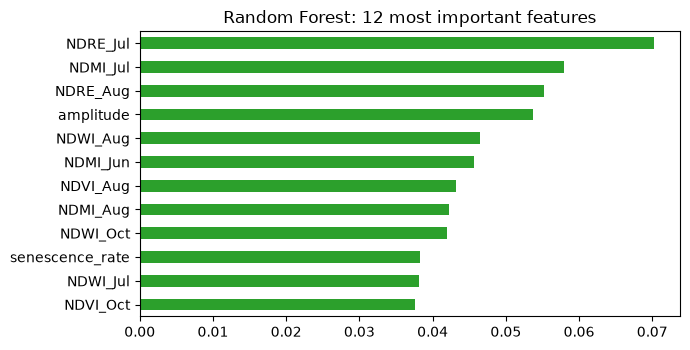

Random Forest on the 60 raw band values: {'OA': 0.904, 'kappa': 0.839, 'macro-F1': 0.686, 'OA 2024': np.float64(0.88), 'OA 2025': np.float64(0.928), 'F1 corn': np.float64(0.943), 'F1 soybeans': np.float64(0.933)}


In [10]:
RESULTS = {}                                                   # model -> dict of test metrics
PROBA = {}                                                     # model -> (len(te), K) test probabilities

def report(name, P, idx=None, store=True):  # score test probabilities and store them
    idx = te if idx is None else idx  # the test samples by default
    yp = P.argmax(1)  # predicted classes
    # report
    rep = ic.classification_report(Y[idx], yp, labels=list(range(K)), class_names=dict(enumerate(CLASSES)))
    # accuracy in each test season
    per_year = {f"OA {y}": (yp[YR[idx] == y] == Y[idx][YR[idx] == y]).mean() for y in (2024, 2025)}
    # headline scores and corn / soybean F1
    r = {"OA": rep["overall_accuracy"], "kappa": rep["kappa"], "macro-F1": rep["macro_f1"], **per_year,
         "F1 corn": rep["per_class"]["f1"].iloc[0], "F1 soybeans": rep["per_class"]["f1"].iloc[1]}
    if store:  # keep the result ...
        RESULTS[name], PROBA[name] = r, P  # ... and the probabilities
    return r, rep  # scores and the full report

t0 = time.time()  # start the timer
rf_trva = np.r_[tr, va]  # training and validation seasons together
# a class-balanced random forest
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, min_samples_leaf=2, class_weight="balanced_subsample")
sub = rng.choice(rf_trva, 80_000, replace=False)  # 80,000 random training samples
rf.fit(FP[sub], Y[sub])  # fit on the phenology features
r, rep_rf = report("RF, phenology features (S2)", rf.predict_proba(FP[te]))  # score the test seasons
# time taken
print(f"Random Forest on {FP.shape[1]} phenology and index features, trained on 2020-2023 in {time.time() - t0:.0f} s")
print({k: round(v, 3) for k, v in r.items()})  # scores
print(rep_rf["per_class"].round(3))  # per-class scores
# the 12 most important features
imp = pd.Series(rf.feature_importances_, index=FEAT_NAMES).sort_values(ascending=False).head(12)
# one panel; bar chart
fig, ax = plt.subplots(figsize=(7, 3.6)); imp.iloc[::-1].plot.barh(ax=ax, color="tab:green")
# title, arrange and draw
ax.set_title("Random Forest: 12 most important features"); plt.tight_layout(); plt.show()

# a second baseline: the same forest on the raw band values of the 6 dates (no feature engineering)
# the same forest on raw values
rf_raw = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, min_samples_leaf=2, class_weight="balanced_subsample")
rf_raw.fit(np.nan_to_num(flat(X2))[sub], Y[sub])  # fit on the 60 band values
r, _ = report("RF, raw bands x dates (S2)", rf_raw.predict_proba(np.nan_to_num(flat(X2))[te]))  # score it
print("Random Forest on the 60 raw band values:", {k: round(v, 3) for k, v in r.items()})  # its scores

**Reading the baseline.** The phenology metrics capture the expected differences: soybeans peak about a month later than corn (median POS day 227 vs 196) with a larger amplitude, and grass, built-up and forest have small amplitudes. But on a six-step monthly grid SOS and EOS are coarse (most pixels cross the threshold between the same two dates), and the metric-based forest (OA ≈ 0.87, macro-F1 ≈ 0.67) is **worse than the same forest on the raw 60 band values** (OA 0.90, macro-F1 0.69). Hand-made metrics compress the curve and lose information; they are most useful for interpretation and for dense series. Both forests do worse in 2024 than in 2025: the 2024 season differs more from the training seasons.


## Temporal deep models: `build_temporal_model`

`build_temporal_model(arch, in_channels, num_classes, n_timesteps=)` returns a PyTorch model for one of six architectures. Pixel models take `(N, T, C)`, the parcel model `(N, T, C, S)` (a set of $S$ pixels per parcel), and the dense models `(N, T, C, H, W)` image patches.

- **TempCNN** (Pelletier et al., 2019): three 1-D convolutions along time, $h^{(l+1)}_t=\mathrm{ReLU}\big(\mathrm{BN}(\sum_{k}W^{(l)}_k h^{(l)}_{t+k}+b^{(l)})\big)$, then a fully connected classifier on the flattened sequence. The kernels learn local temporal shapes (a rise, a peak) at fixed positions in the season.
- **LSTM** (bidirectional): a recurrent cell with gates, $c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t$, $h_t=o_t\odot\tanh c_t$, reads the sequence in both directions; the final state is classified.
- **L-TAE** (Garnot & Landrieu, 2020): each date is embedded and given a sinusoidal encoding of its **day of year** $p$, $\mathrm{PE}(p)_{2i}=\sin(p/1000^{2i/d})$; a learned *master query* $q$ attends over the dates, $\alpha_t=\mathrm{softmax}_t\big(q^\top W_K h_t/\sqrt d\big)$, $z=\sum_t\alpha_t W_V h_t$. Because positions are days, not indices, it can in principle handle irregular series.
- **PSE-TAE** (Garnot et al., 2020): for a parcel, a shared MLP embeds each of the $S$ pixels at each date, the set is summarised by its mean and standard deviation (order-invariant), and an L-TAE models time.
- **ConvLSTM** (Shi et al., 2015): an LSTM whose gates are 2-D convolutions, so hidden states are maps; the final state gives a class map.
- **U-TAE** (Garnot & Landrieu, 2021): a shared 2-D encoder on every date, temporal attention at the coarsest level giving per-pixel weights over dates, which are upsampled to aggregate the skip features, and a U-Net decoder.

All are trained with `train_model` (AdamW, cosine schedule, early stopping on the 2023 validation season, gradient clipping) and **square-root inverse class weights** in the cross-entropy, $w_k\propto 1/\sqrt{n_k}$. Inputs are standardised per band with a `Normalizer` fitted on the training seasons only.

### Pixel models: TempCNN, LSTM, L-TAE


In [11]:
# training-only normalisation of the (N, T, C) series, per band (band axis 2)
NORM2 = ic.Normalizer("zscore").fit(X2[tr], band_axis=2)
NORM1 = ic.Normalizer("zscore").fit(X1[tr], band_axis=2)  # the same for Sentinel-1
# normalised optical series, missing as 0
X2n = np.nan_to_num(NORM2.transform(X2, band_axis=2)).astype("float32")
X1n = np.nan_to_num(NORM1.transform(X1, band_axis=2)).astype("float32")  # normalised SAR series
POS = np.broadcast_to(TGRID.astype("float32"), (len(Y), len(TGRID)))      # day of year of each step, for the attention models
CW = ic.class_weights(Y[tr], num_classes=K, method="sqrt_inverse")  # class weights against imbalance
print("class weights (sqrt-inverse):", dict(zip(CLASSES, CW.round(2))))  # show them

class SeqDataset:  # sequences as a PyTorch dataset
    """(N, T, C) sequences, optionally with day-of-year positions; items are {"image", "label"} dicts.
    With positions the image is a tuple (x, positions), which train_model passes to model(x, positions)."""
    def __init__(self, X, y=None, pos=None):  # store the arrays
        self.X, self.y, self.pos = X, y, pos  # ...
    def __len__(self):  # number of samples
        return len(self.X)  # ...
    def __getitem__(self, i):  # one sample
        x = torch.from_numpy(np.ascontiguousarray(self.X[i]))  # the sequence as a tensor
        # with day-of-year positions when given
        img = x if self.pos is None else (x, torch.from_numpy(np.ascontiguousarray(self.pos[i])))
        # image and, if available, label
        return {"image": img} if self.y is None else {"image": img, "label": torch.as_tensor(self.y[i])}

# train a sequence model on two index sets
def fit_seq(model, Xa, idx_tr, idx_va, pos=None, epochs=EPOCHS, lr=1e-3, bs=512, label=""):
    # shuffled training batches
    ld_tr = ic.as_loader(SeqDataset(Xa[idx_tr], Y[idx_tr], None if pos is None else pos[idx_tr]), bs, shuffle=True, seed=SEED)
    # validation batches
    ld_va = ic.as_loader(SeqDataset(Xa[idx_va], Y[idx_va], None if pos is None else pos[idx_va]), 2048, shuffle=False)
    t0 = time.time()  # start the timer
    # the GeoLattice training loop with weighted cross-entropy
    hist = ic.train_model(model, ld_tr, ld_va, epochs=epochs, loss=ic.get_loss("weighted_ce", class_weights=CW),
                          optimizer="adamw", lr=lr, scheduler="cosine", early_stopping=8, monitor="val_score",
                          num_classes=K, device=DEVICE, seed=SEED, verbose=False)
    return model, hist, time.time() - t0  # model, history and time

def proba_seq(model, Xa, idx, pos=None):  # class probabilities of samples idx
    # batches in order
    ld = ic.as_loader(SeqDataset(Xa[idx], None, None if pos is None else pos[idx]), 4096, shuffle=False)
    return ic.predict_proba_batches(model, ld, device=DEVICE)  # probabilities

C2, T = X2.shape[2], X2.shape[1]  # number of optical bands and dates
# the three pixel models; L-TAE uses day-of-year positions
PIX_MODELS = {"TempCNN": (lambda c: ic.build_temporal_model("tempcnn", in_channels=c, num_classes=K, n_timesteps=T), False),
              "LSTM": (lambda c: ic.build_temporal_model("lstm", in_channels=c, num_classes=K), False),
              "L-TAE": (lambda c: ic.build_temporal_model("ltae", in_channels=c, num_classes=K), True)}
HIST, MODELS = {}, {}  # histories and models
rows = []  # one row per model
for name, (make, use_pos) in PIX_MODELS.items():  # each model
    m = make(C2)  # build it
    m, h, sec = fit_seq(m, X2n, tr, va, POS if use_pos else None)  # train on 2020-2022, validate on 2023
    P = proba_seq(m, X2n, te, POS if use_pos else None)  # test probabilities
    r, _ = report(f"{name} (S2)", P)  # scores
    HIST[name], MODELS[name] = h, m  # keep history and model
    # size, epochs, time and scores
    rows.append({"model": name, "parameters": ic.count_parameters(m), "epochs run": len(h["val_score"]),
                 "best val OA (2023)": max(h["val_score"]), "seconds": round(sec), **{k: r[k] for k in ("OA", "macro-F1", "OA 2024", "OA 2025")}})
pd.DataFrame(rows).set_index("model").round(3)  # as a table

class weights (sqrt-inverse): {'Corn': np.float32(0.26), 'Soybeans': np.float32(0.3), 'Grass/pasture': np.float32(0.96), 'Developed': np.float32(0.88), 'Wetland/forest': np.float32(1.48), 'Other': np.float32(2.11)}


,parameters,epochs run,best val OA (2023),seconds,OA,macro-F1,OA 2024,OA 2025
model,,,,,,,,
TempCNN,145350,30,0.937,42,0.905,0.698,0.902,0.908
LSTM,139014,13,0.935,20,0.907,0.702,0.903,0.911
L-TAE,22086,10,0.933,19,0.879,0.660,0.854,0.903


**Reading the pixel models.** TempCNN and LSTM reach OA 0.90 to 0.91 and macro-F1 ≈ 0.70 on the unseen seasons, at or slightly above the raw-band Random Forest, and are about equally good in 2024 and 2025. L-TAE stops early and does clearly worse on 2024: with only six regularly spaced dates its main advantage (day-of-year positions for irregular series) is not used, and attention over six tokens has little to work with. These are single runs; differences of about 0.005 are within seed noise.

### Parcels: PSE-TAE

PSE-TAE needs parcels. The AOI has no field boundaries, so we build **parcel proxies**: connected pixels that share the same **six-year CDL sequence** (a field keeps its rotation history; its neighbour almost never has an identical one), eroded by one pixel to drop mixed edges, and at least 2.5 ha. For each parcel we draw $S=16$ pixels and build their series at every date.


1,702 parcels of at least 2.5 ha (median 24.8 ha, 71 % of the labelled area)


parcel-year samples: {'train': 5106, 'val': 1702, 'test': 3404}
parcel classes (test years): {'Corn': 1883, 'Soybeans': 1381, 'Grass/pasture': 73, 'Wetland/forest': 28, 'Other': 25, 'Developed': 14}


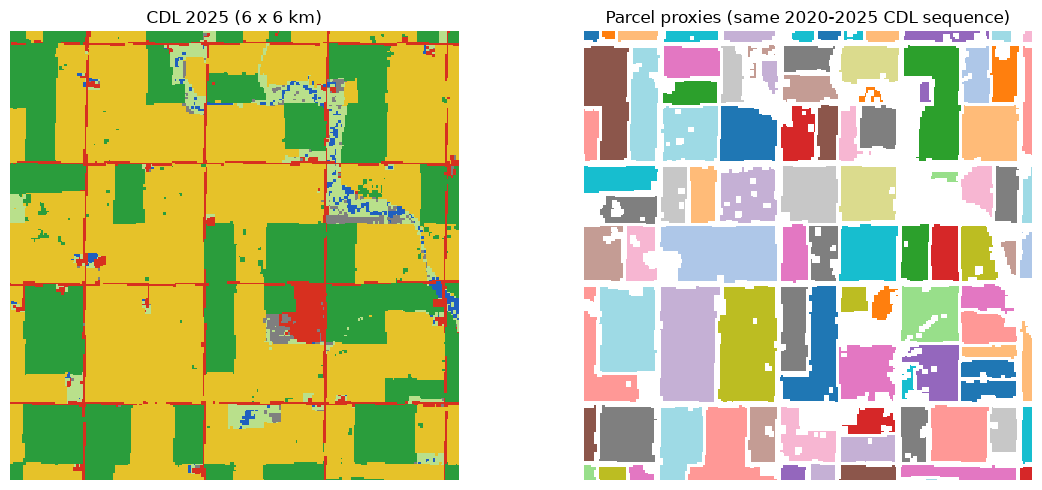

In [12]:
from skimage.measure import label as cc_label  # connected-component labelling
# parcel proxies: connected pixels that share the same 6-year CDL sequence (a field keeps its rotation history;
# its neighbour almost never has the identical one). One pixel of erosion removes mixed edge pixels.
code = np.zeros(cdl.shape[1:], "int64")
for i in range(len(YEARS)):  # each year ...
    code = code * K + np.clip(cdl[i], 0, None)  # ... adds one digit of the class sequence
code[~labelled] = -1  # no label in some year
parcel = cc_label(code + 1, background=0, connectivity=1)  # connected pixels with the same sequence
# pixels whose 3 x 3 neighbourhood is the same parcel
interior = ndi.binary_erosion(parcel > 0, iterations=1) & (ndi.minimum_filter(parcel, 3) == ndi.maximum_filter(parcel, 3))
parcel = np.where(interior, parcel, 0)  # drop edge pixels
size = np.bincount(parcel.ravel())  # pixels per parcel
MIN_PX = 62                                                   # 2.5 ha at 20 m
keep = np.flatnonzero(size >= MIN_PX); keep = keep[keep > 0]  # parcels of at least 2.5 ha
# number, size and share of the area
print(f"{len(keep):,} parcels of at least {MIN_PX * 0.04:.1f} ha (median {np.median(size[keep]) * 0.04:.1f} ha, "
      f"{size[keep].sum() / labelled.sum() * 100:.0f} % of the labelled area)")

S = 16                                                        # pixels drawn per parcel (with replacement in small parcels)
order = np.argsort(parcel.ravel(), kind="stable")  # pixels sorted by parcel id
starts = np.searchsorted(parcel.ravel()[order], keep)  # where each parcel starts
pix = np.stack([order[s + rng.integers(0, size[p], S)] for s, p in zip(starts, keep)])      # (P, S) flat pixel indices
pr, pc = np.unravel_index(pix, parcel.shape)  # their rows and columns
s2v = S2C.values[:, :, pr, pc]                                # (34, 10, P, S)
s1v = S1C.values[:, :, pr, pc]  # SAR values at those pixels
P_ = len(keep)  # number of parcels
PX2, PX1 = {}, {}  # per-year parcel series
for y in YEARS:  # each year
    i2, i1 = np.flatnonzero(d_s2.year == y), np.flatnonzero(d_s1.year == y)  # its optical and SAR dates
    a = np.moveaxis(s2v[i2], (2, 3), (0, 1)).reshape(P_ * S, len(i2), C2)  # (P*S, T, C) optical
    b = np.moveaxis(s1v[i1], (2, 3), (0, 1)).reshape(P_ * S, len(i1), 2)  # (P*S, T, 2) SAR
    PX2[y] = interp_series(a, d_s2[i2].dayofyear.values)[0].reshape(P_, S, 6, C2)  # interpolated to the 6 days
    PX1[y] = interp_series(b, d_s1[i1].dayofyear.values)[0].reshape(P_, S, 6, 2)  # ...
# parcel-year samples: (P*6, T, C, S); the label is the (single) CDL class of the parcel in that year
PXS = np.concatenate([np.moveaxis(PX2[y], 1, -1) for y in YEARS])                       # (P*6, 6, 10, S)
# CDL class of each parcel and year
PY = np.concatenate([cdl[i][pr[:, 0], pc[:, 0]] for i in range(len(YEARS))]).astype("int64")
PYR = np.repeat(YEARS, P_)  # year of each sample
# train 2020-2022, validate 2023, test 2024-2025
psp = ic.temporal_split(pd.to_datetime([f"{y}-12-31" for y in PYR]), train_end="2022-12-31", val_end="2023-12-31")
# split sizes
print("parcel-year samples:", {k: len(v) for k, v in [("train", psp.train), ("val", psp.val), ("test", psp.test)]})
# classes of the test parcels
print("parcel classes (test years):", pd.Series(PY[psp.test]).map(dict(enumerate(CLASSES))).value_counts().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 5))  # two panels
zoom = (slice(400, 700), slice(500, 800))  # a 300 x 300 pixel zoom
# CDL zoom
ax[0].imshow(np.where(cdl[-1] < 0, np.nan, cdl[-1])[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[0].set_title("CDL 2025 (6 x 6 km)")
pm = np.where(np.isin(parcel, keep), parcel % 20, np.nan)  # parcel ids for display
# parcels zoom
ax[1].imshow(pm[zoom], cmap="tab20", interpolation="nearest"); ax[1].set_title("Parcel proxies (same 2020-2025 CDL sequence)")
for a in ax:  # every panel
    a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

The parcel proxies match the visible field pattern (quarter-sections and their halves) and cover 71 % of the labelled area. Their labels are pure by construction, so this is an easier task than pixel classification; the comparison below is therefore between models on the **same parcels**.


In [13]:
# train a sequence model on explicit arrays
def fit_xy(model, Xtr_, ytr_, Xva_, yva_, pos_tr=None, pos_va=None, epochs=EPOCHS, lr=1e-3, bs=256, cw=CW):
    # shuffled training batches
    ld_tr = ic.as_loader(SeqDataset(Xtr_, ytr_, pos_tr), bs, shuffle=True, seed=SEED)
    ld_va = ic.as_loader(SeqDataset(Xva_, yva_, pos_va), 1024, shuffle=False)  # validation batches
    t0 = time.time()  # start the timer
    # the GeoLattice training loop
    h = ic.train_model(model, ld_tr, ld_va, epochs=epochs, loss=ic.get_loss("weighted_ce", class_weights=cw), optimizer="adamw",
                       lr=lr, scheduler="cosine", early_stopping=8, monitor="val_score", num_classes=K, device=DEVICE,
                       seed=SEED, verbose=False)
    return model, h, time.time() - t0  # model, history and time

PXn = np.nan_to_num(NORM2.transform(PXS, band_axis=2)).astype("float32")            # (P*6, T, C, S)
PPOS = np.broadcast_to(TGRID.astype("float32"), (len(PY), len(TGRID)))  # day-of-year positions
ptr, pva, pte = psp.train, psp.val, psp.test  # parcel split
# PSE-TAE (pixel-set encoder + temporal attention)
pse = ic.build_temporal_model("psetae", in_channels=C2, num_classes=K)
pse, h_pse, sec = fit_xy(pse, PXn[ptr], PY[ptr], PXn[pva], PY[pva], PPOS[ptr], PPOS[pva], epochs=60)  # train it
# test probabilities
P_pse = ic.predict_proba_batches(pse, ic.as_loader(SeqDataset(PXn[pte], None, PPOS[pte]), 1024, shuffle=False), device=DEVICE)

# the pixel models on the same parcels: classify each of the S pixels, average the probabilities per parcel
pix_in = np.moveaxis(PXn[pte], -1, 1).reshape(-1, len(TGRID), C2)                  # (n*S, T, C)
rows = {}  # one row per approach
def parcel_scores(name, P):  # parcel-level scores
    # report
    rep = ic.classification_report(PY[pte], P.argmax(1), labels=list(range(K)), class_names=dict(enumerate(CLASSES)))
    rows[name] = {"parcel OA": rep["overall_accuracy"], "parcel macro-F1": rep["macro_f1"],  # scores
                  "F1 corn": rep["per_class"]["f1"].iloc[0], "F1 soybeans": rep["per_class"]["f1"].iloc[1]}
# PSE-TAE
parcel_scores(f"PSE-TAE ({ic.count_parameters(pse):,} parameters, {len(h_pse['val_score'])} epochs)", P_pse)
for name, (make, use_pos) in PIX_MODELS.items():  # each pixel model
    # probabilities of every pixel of the test parcels
    pp = proba_seq(MODELS[name], pix_in, np.arange(len(pix_in)), np.broadcast_to(TGRID.astype("float32"), (len(pix_in), 6)) if use_pos else None)
    # averaged per parcel
    parcel_scores(f"{name} on pixels, averaged per parcel", pp.reshape(len(pte), S, K).mean(1))
    parcel_scores(f"{name}, one pixel per parcel", pp.reshape(len(pte), S, K)[:, 0])  # one pixel per parcel
print(f"test parcel-years: {len(pte):,} (2024-2025)")  # number of test parcel-years
pd.DataFrame(rows).T.round(3)  # show the comparison

test parcel-years: 3,404 (2024-2025)


,parcel OA,parcel macro-F1,F1 corn,F1 soybeans
"PSE-TAE (26,950 parameters, 27 epochs)",0.984,0.888,0.991,0.991
"TempCNN on pixels, averaged per parcel",0.994,0.975,0.996,0.994
"TempCNN, one pixel per parcel",0.980,0.899,0.987,0.982
"LSTM on pixels, averaged per parcel",0.992,0.959,0.995,0.992
"LSTM, one pixel per parcel",0.979,0.845,0.989,0.982
"L-TAE on pixels, averaged per parcel",0.966,0.920,0.972,0.964
"L-TAE, one pixel per parcel",0.948,0.831,0.958,0.950


**Reading the parcel results.** PSE-TAE classifies 98.4 % of the test parcel-years correctly (macro-F1 0.89), but the pixel TempCNN applied to the same 16 pixels and **averaged per parcel** does better (99.4 %, macro-F1 0.98). PSE-TAE is trained on only 5 106 parcel-years, the pixel models on 120 000 pixel-years; with this little parcel data, a pixel model plus aggregation wins. Averaging also beats classifying a single pixel of the parcel (0.981), which shows how much of the pixel error is noise that cancels within a field. PSE-TAE pays off with many parcels (PASTIS has about 125 000).

### Patches: ConvLSTM and U-TAE

The dense models need complete image cubes. `interp_cube` applies exactly the same interpolation as `interp_series` to every pixel of a season; the 1456 × 1516 px image is cut into 32 × 32 px patches (640 m), 2 115 per season, with the CDL as dense labels (`-100` = ignored).


In [14]:
def interp_cube(A, doy, target=TGRID):  # interpolate a whole (T, C, H, W) cube onto the 6 days
    """Whole-image version: the (T, C, H, W) cube is reshaped to (H*W, T, C) pixel series and passed
    through interp_series, so the rule is exactly the same as for the sampled pixels."""
    T_, C_, H_, W_ = A.shape  # cube dimensions
    out, _ = interp_series(A.reshape(T_, C_, -1).transpose(2, 0, 1), doy, target)  # every pixel as a series
    return out.transpose(1, 2, 0).reshape(len(target), C_, H_, W_)  # back to (6, C, H, W)

t0 = time.time()  # start the timer
CUBE2, CUBE1 = {}, {}  # interpolated cubes per year
for y in YEARS:  # each year
    i2, i1 = np.flatnonzero(d_s2.year == y), np.flatnonzero(d_s1.year == y)  # its dates
    CUBE2[y] = interp_cube(S2C.values[i2], d_s2[i2].dayofyear.values)          # (6, 10, H, W)
    CUBE1[y] = interp_cube(S1C.values[i1], d_s1[i1].dayofyear.values)          # (6, 2, H, W)
print(f"interpolated full cubes for {len(YEARS)} years in {time.time() - t0:.0f} s "  # time and memory
      f"({sum(c.nbytes for c in CUBE2.values()) / 1e9:.1f} GB optical)")
# check against the per-pixel version at the sample locations
dev = np.nanmax(np.abs(CUBE2[2024][:, :, rr, cc].transpose(2, 0, 1) - S2Y[2024]))
# the cube agrees with the per-pixel result
print(f"largest difference from interp_series at the 40 000 sample pixels (2024): {dev:.2e}")

interpolated full cubes for 6 years in 43 s (3.2 GB optical)
largest difference from interp_series at the 40 000 sample pixels (2024): 0.00e+00


In [15]:
PS = 32                                                   # 32 x 32 px patches = 640 m at 20 m
H, W = REF.shape  # grid size
nr, nc = H // PS, W // PS  # patch rows and columns
def patches(y, cube):  # (N, T, C, 32, 32) patches of a year
    # the cube cropped to whole patches
    c = (cube if cube is not None else CUBE2)[y][:, :, : nr * PS, : nc * PS]
    T_, C_ = c.shape[:2]  # dates and bands
    # reshape into patches
    return c.reshape(T_, C_, nr, PS, nc, PS).transpose(2, 4, 0, 1, 3, 5).reshape(nr * nc, T_, C_, PS, PS)
def label_patches(i):  # label patches of a year
    # reshape the CDL into patches
    l = cdl[i][: nr * PS, : nc * PS].reshape(nr, PS, nc, PS).transpose(0, 2, 1, 3).reshape(nr * nc, PS, PS)
    return np.where(l < 0, -100, l).astype("int64")  # no data as -100 (ignored by the loss)

# normalised patches per year
PATCH_X = {y: np.nan_to_num(NORM2.transform(patches(y, CUBE2), band_axis=2)).astype("float32") for y in YEARS}
PATCH_Y = {y: label_patches(i) for i, y in enumerate(YEARS)}  # label patches per year
# patches per year and input shape
print(f"{nr * nc} patches of {PS} x {PS} px per year; input (N, T, C, H, W) = {PATCH_X[2020].shape}")
# training patches: 2020-2022
p_tr = (np.concatenate([PATCH_X[y] for y in (2020, 2021, 2022)]), np.concatenate([PATCH_Y[y] for y in (2020, 2021, 2022)]))
p_va = (PATCH_X[2023], PATCH_Y[2023])  # validation patches: 2023
# test patches: 2024-2025
p_te_x, p_te_y = np.concatenate([PATCH_X[y] for y in (2024, 2025)]), np.concatenate([PATCH_Y[y] for y in (2024, 2025)])

def fit_dense(model, epochs, lr=1e-3, bs=16):  # train a dense (per-pixel) model on the patches
    ld_tr = ic.as_loader(SeqDataset(*p_tr), bs, shuffle=True, seed=SEED)  # shuffled training batches
    ld_va = ic.as_loader(SeqDataset(*p_va), 32, shuffle=False)  # validation batches
    t0 = time.time()  # start the timer
    # GeoLattice training loop in segmentation mode
    h = ic.train_model(model, ld_tr, ld_va, task="segmentation", epochs=epochs,
                       loss=ic.get_loss("weighted_ce", class_weights=CW, ignore_index=-100), optimizer="adamw", lr=lr,
                       scheduler="cosine", early_stopping=6, monitor="val_score", num_classes=K, ignore_index=-100,
                       device=DEVICE, seed=SEED, verbose=False)
    return model, h, time.time() - t0  # model, history and time

def dense_scores(P, yt):  # pixel scores of a dense prediction
    pred = P.argmax(1)  # predicted classes
    m = yt >= 0  # labelled pixels
    # report
    rep = ic.classification_report(yt[m], pred[m], labels=list(range(K)), class_names=dict(enumerate(CLASSES)))
    cm = np.asarray(rep["confusion_matrix"], float)  # confusion matrix
    iou = np.diag(cm) / (cm.sum(0) + cm.sum(1) - np.diag(cm))  # IoU per class
    # the scores
    return {"pixel OA": rep["overall_accuracy"], "macro-F1": rep["macro_f1"], "mIoU": np.nanmean(iou),
            "F1 corn": rep["per_class"]["f1"].iloc[0], "F1 soybeans": rep["per_class"]["f1"].iloc[1]}

DENSE, DENSE_P = {}, {}  # results and probabilities
EP_D = 25 if DEVICE == "cuda" else 4  # epochs (fewer on a CPU)
for name, kw in [("ConvLSTM", {"hidden": 32}), ("U-TAE", {"widths": (32, 64, 128)})]:  # ConvLSTM and U-TAE
    # build the model
    m = ic.build_temporal_model(name.lower().replace("-", ""), in_channels=C2, num_classes=K, **kw)
    m, h, sec = fit_dense(m, EP_D)  # train it
    # test probabilities
    P = ic.predict_proba_batches(m, ic.as_loader(SeqDataset(p_te_x), 32, shuffle=False), device=DEVICE)
    DENSE_P[name] = P  # keep them
    # size, epochs, time and scores
    DENSE[name] = {"parameters": ic.count_parameters(m), "epochs run": len(h["val_score"]), "minutes": sec / 60,
                   "best val mIoU (2023)": max(h["val_score"]), **dense_scores(P, p_te_y)}
    MODELS[name] = m  # keep the model

# the pixel TempCNN applied to every pixel of the same test patches
xt = np.moveaxis(p_te_x, (3, 4), (1, 2)).reshape(-1, len(TGRID), C2)
# TempCNN probabilities back as (N, K, 32, 32)
Pt = proba_seq(MODELS["TempCNN"], xt, np.arange(len(xt))).reshape(len(p_te_x), PS, PS, K).transpose(0, 3, 1, 2)
DENSE_P["TempCNN (per pixel)"] = Pt  # keep them
# its scores
DENSE["TempCNN (per pixel)"] = {"parameters": ic.count_parameters(MODELS["TempCNN"]), **dense_scores(Pt, p_te_y)}
pd.DataFrame(DENSE).T.round(3)  # the comparison

2115 patches of 32 x 32 px per year; input (N, T, C, H, W) = (2115, 6, 10, 32, 32)


,parameters,epochs run,minutes,best val mIoU (2023),pixel OA,macro-F1,mIoU,F1 corn,F1 soybeans
ConvLSTM,48710.0,17.0,0.913,0.677,0.910,0.719,0.590,0.950,0.942
U-TAE,552038.0,18.0,1.614,0.654,0.900,0.702,0.575,0.940,0.935
TempCNN (per pixel),145350.0,NaN,NaN,NaN,0.908,0.699,0.570,0.953,0.945


**Reading the patch models.** ConvLSTM reaches pixel OA 0.910, about the same as the pixel TempCNN on the same patches (0.907), with a slightly higher mIoU (0.59 vs 0.57); U-TAE is a little lower (0.894). In this landscape of large, homogeneous fields the temporal signal carries almost all the information and spatial context adds little; the dense models also have fewer independent training samples (6 345 patches). U-TAE is the state of the art on PASTIS, with smaller and more varied parcels and many more dates; with six monthly dates its temporal attention has little to choose from.


## Optical-SAR fusion: early, middle and late, and which wins under cloud

| Fusion | Where the sensors meet | Here |
|---|---|---|
| **Early** | at the input: bands stacked per date | `fuse_early` (one date, xarray) and a TempCNN on the 12-channel series |
| **Middle** | in the feature space: separate branches, features concatenated | `build_fusion_model`: two-branch CNN on 7 × 7 chips, dates stacked as channels |
| **Late** | at the decision: probabilities of separate models averaged | `fuse_late(probabilities, weights)` of the optical and the SAR TempCNN |

For late fusion the optical weight $w$ in $\mathbf p=w\,\mathbf p_{opt}+(1-w)\,\mathbf p_{SAR}$ is chosen on the 2023 validation season.


In [16]:
# fuse_early on one date: optical and SAR bands stacked on the shared 20 m grid
opt_day = S2C.sel(time="2025-08-26").squeeze(drop=True).to_dataset("band").rio.write_crs(REF.rio.crs)
# SAR of 13 August 2025
sar_day = S1C.sel(time="2025-08-13").squeeze(drop=True).to_dataset("band").rio.write_crs(REF.rio.crs)
stack = ic.fuse_early(opt_day, sar_day)  # early fusion: stack the bands
# shape, band names and attributes
print("fuse_early:", tuple(stack.shape), list(stack.band.values), stack.attrs)

def tempcnn(c):  # TempCNN with c input channels
    return ic.build_temporal_model("tempcnn", in_channels=c, num_classes=K, n_timesteps=len(TGRID))  # ...

# SAR only, and early fusion of the two time series (12 channels per date)
XE = np.concatenate([X2n, X1n], 2)
FUS = {}  # fusion models
FUS["SAR only (TempCNN)"], _, _ = fit_seq(tempcnn(2), X1n, tr, va)  # SAR only
FUS["Early fusion (TempCNN)"], _, _ = fit_seq(tempcnn(12), XE, tr, va)  # optical and SAR stacked
FUS["Optical only (TempCNN)"] = MODELS["TempCNN"]  # optical only (trained earlier)

# late fusion: the weight of the optical model is chosen on the 2023 validation season
P_va = {k: proba_seq(FUS[k], X, va) for k, X in [("Optical only (TempCNN)", X2n), ("SAR only (TempCNN)", X1n)]}
grid = np.linspace(0, 1, 11)  # optical weights 0, 0.1, ... 1
# validation accuracy of each weight
acc_w = [(ic.fuse_late([P_va["Optical only (TempCNN)"], P_va["SAR only (TempCNN)"]], weights=[w, 1 - w]).argmax(1) == Y[va]).mean() for w in grid]
W_OPT = float(grid[int(np.argmax(acc_w))])  # the best weight
print(f"late fusion: optical weight chosen on 2023 = {W_OPT:.1f} (validation OA {max(acc_w):.3f})")  # report it

fuse_early: (12, 1456, 1516) [np.str_('opt_blue'), np.str_('opt_green'), np.str_('opt_red'), np.str_('opt_rededge1'), np.str_('opt_rededge2'), np.str_('opt_rededge3'), np.str_('opt_nir'), np.str_('opt_nir08'), np.str_('opt_swir16'), np.str_('opt_swir22'), np.str_('sar_vv'), np.str_('sar_vh')] {'fusion': 'early', 'aligned': False}


late fusion: optical weight chosen on 2023 = 0.8 (validation OA 0.939)


In [17]:
# middle fusion: build_fusion_model is a two-branch chip classifier; each branch sees a 7 x 7 px chip with
# the 6 dates stacked as channels (optical 60, SAR 12); the label is the class of the centre pixel
CH = 3                                                       # half-width: 7 x 7 chips
# normalised, padded optical cubes
CN2 = {y: np.pad(np.nan_to_num(NORM2.transform(CUBE2[y], band_axis=1)), ((0, 0), (0, 0), (CH, CH), (CH, CH)), mode="reflect").astype("float32") for y in YEARS}
# normalised, padded SAR cubes
CN1 = {y: np.pad(np.nan_to_num(NORM1.transform(CUBE1[y], band_axis=1)), ((0, 0), (0, 0), (CH, CH), (CH, CH)), mode="reflect").astype("float32") for y in YEARS}
win = np.arange(-CH, CH + 1)  # window offsets
def chips(cube, idx):  # 7 x 7 chips of samples idx
    yr_, r_, c_ = YR[idx], rr[LOC[idx]] + CH, cc[LOC[idx]] + CH  # year, row and column of each sample
    # output array
    out = np.empty((len(idx), cube[YEARS[0]].shape[0] * cube[YEARS[0]].shape[1], 2 * CH + 1, 2 * CH + 1), "float32")
    for y in np.unique(yr_):  # each year
        m = yr_ == y  # its samples
        a = cube[y][:, :, r_[m][:, None, None] + win[None, :, None], c_[m][:, None, None] + win[None, None, :]]   # (T, C, n, 7, 7)
        out[m] = a.transpose(2, 0, 1, 3, 4).reshape(m.sum(), -1, 2 * CH + 1, 2 * CH + 1)  # (n, T*C, 7, 7)
    return out  # the chips

class PairDataset:  # a dataset of optical/SAR chip pairs
    def __init__(self, a, b, y=None):  # store them
        self.a, self.b, self.y = a, b, y  # ...
    def __len__(self):  # number of samples
        return len(self.a)  # ...
    def __getitem__(self, i):  # one sample
        img = (torch.from_numpy(self.a[i]), torch.from_numpy(self.b[i]))  # both chips
        # image and, if available, label
        return {"image": img} if self.y is None else {"image": img, "label": torch.as_tensor(self.y[i])}

# random training and validation subsets
sub_tr = rng.choice(tr, 60_000, replace=False); sub_va = rng.choice(va, 20_000, replace=False)
mid = ic.build_fusion_model(len(TGRID) * C2, len(TGRID) * 2, K, width=32)  # two-branch fusion CNN
t0 = time.time()  # start the timer
# training batches
ld_tr = ic.as_loader(PairDataset(chips(CN2, sub_tr), chips(CN1, sub_tr), Y[sub_tr]), 256, shuffle=True, seed=SEED)
# validation batches
ld_va = ic.as_loader(PairDataset(chips(CN2, sub_va), chips(CN1, sub_va), Y[sub_va]), 1024, shuffle=False)
# train it
h_mid = ic.train_model(mid, ld_tr, ld_va, epochs=EPOCHS, loss=ic.get_loss("weighted_ce", class_weights=CW), optimizer="adamw",
                       lr=1e-3, scheduler="cosine", early_stopping=8, monitor="val_score", num_classes=K, device=DEVICE,
                       seed=SEED, verbose=False)
FUS["Middle fusion (two-branch CNN, 7 x 7 chips)"] = mid  # keep the model
# size, epochs, time and accuracy
print(f"middle fusion: {ic.count_parameters(mid):,} parameters, {len(h_mid['val_score'])} epochs, {time.time() - t0:.0f} s, "
      f"best validation OA {max(h_mid['val_score']):.3f}")

middle fusion: 159,174 parameters, 23 epochs, 36 s, best validation OA 0.929


### Which wins under cloud?

The archive was screened for clear images, so we **simulate clouds** on the test seasons: each optical acquisition of a test pixel is lost with probability $r$ (for the chips, over all 49 pixels at once), and the remaining dates are re-interpolated with the same `interp_series`. SAR is unaffected. With $r=1$ no optical data are left at all. Two more variants are tested:

- **early fusion trained with simulated clouds**: a second copy of the training seasons with a random loss rate per pixel, so the network learns to fall back on SAR;
- **late fusion with availability weights**: per pixel, the optical weight is scaled by the share of optical dates actually observed, $w_i=w\cdot n_i^{obs}/n_i$.


cloud experiment in 96 s


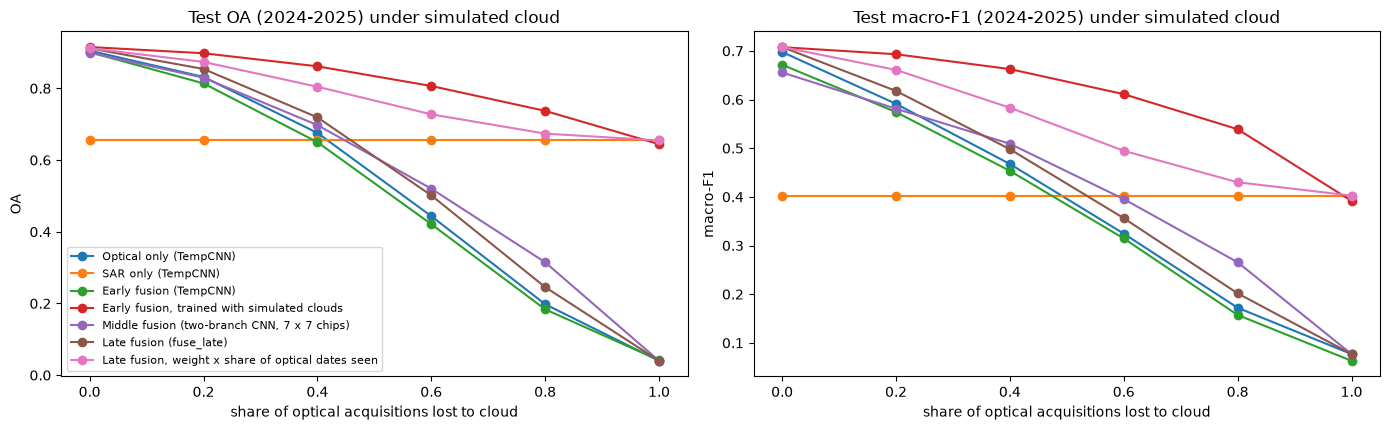

cloud rate,0.0,0.2,0.4,0.6,0.8,1.0
model,,,,,,
Early fusion (TempCNN),0.901,0.814,0.650,0.421,0.184,0.042
"Early fusion, trained with simulated clouds",0.915,0.898,0.862,0.807,0.737,0.644
Late fusion (fuse_late),0.912,0.854,0.719,0.501,0.246,0.040
"Late fusion, weight x share of optical dates seen",0.912,0.874,0.805,0.728,0.674,0.655
"Middle fusion (two-branch CNN, 7 x 7 chips)",0.899,0.830,0.698,0.520,0.315,0.040
Optical only (TempCNN),0.905,0.832,0.676,0.444,0.198,0.040
SAR only (TempCNN),0.655,0.655,0.655,0.655,0.655,0.655


In [18]:
# Simulated clouds: each optical acquisition of a test pixel is lost with probability `rate`; the remaining
# dates are re-interpolated with interp_series (rate 1 = no optical data at all: the normalised series is 0).
# SAR is not affected. Chips lose the same dates over all their 49 pixels (a cloud covers the chip).
TEST_YEARS = (2024, 2025)
I2 = {y: np.flatnonzero(d_s2.year == y) for y in YEARS}  # optical date indices per year
DOY2 = {y: d_s2[I2[y]].dayofyear.values for y in YEARS}  # their days of year

def optical_series(y, mask, locs=slice(None)):  # normalised optical series of a year with masked dates
    raw = X_s2[locs][:, I2[y]].copy()  # raw values of those dates
    raw[mask] = np.nan  # drop the masked ones
    # re-interpolate and normalise
    return np.nan_to_num(NORM2.transform(interp_series(raw, DOY2[y])[0], band_axis=2)).astype("float32")

def raw_chips(y):  # 7 x 7 optical chips of every location
    # padded cube of the year
    a = np.pad(S2C.values[I2[y]], ((0, 0), (0, 0), (CH, CH), (CH, CH)), mode="reflect")
    a = a[:, :, rr[:, None, None] + CH + win[None, :, None], cc[:, None, None] + CH + win[None, None, :]]   # (T, C, N, 7, 7)
    return a.transpose(2, 3, 4, 0, 1).reshape(N_LOC, (2 * CH + 1) ** 2, len(I2[y]), C2)  # (N, 49, T, C)
RAWCH = {y: raw_chips(y) for y in TEST_YEARS}  # for both test seasons
CH1_TE = chips(CN1, te)  # SAR chips of the test samples

def degraded_test(rate, seed=0):  # test inputs with a share `rate` of optical dates lost
    g = np.random.default_rng(seed)  # random generator
    xs, cs, seen = [], [], []  # optical series, chips and observed shares
    for y in TEST_YEARS:  # both test seasons
        mask = g.random((N_LOC, len(I2[y]))) < rate  # dates lost per location
        seen.append(1 - mask.mean(1))                         # share of the optical dates still observed
        xs.append(optical_series(y, mask))  # the degraded optical series
        # chips lose the same dates
        c = RAWCH[y].copy(); c[np.broadcast_to(mask[:, None, :], c.shape[:3])] = np.nan
        ci = interp_series(c.reshape(-1, len(I2[y]), C2), DOY2[y])[0]  # re-interpolate every chip pixel
        # normalise
        ci = np.nan_to_num(NORM2.transform(ci, band_axis=2)).reshape(N_LOC, (2 * CH + 1) ** 2, len(TGRID), C2)
        # back to (N, T*C, 7, 7)
        cs.append(ci.reshape(N_LOC, 2 * CH + 1, 2 * CH + 1, len(TGRID), C2).transpose(0, 3, 4, 1, 2).reshape(N_LOC, -1, 2 * CH + 1, 2 * CH + 1))
    return np.concatenate(xs), np.concatenate(cs).astype("float32"), np.concatenate(seen)  # all test samples

# early fusion trained WITH simulated clouds: a second copy of the training seasons with a random loss rate per pixel
g = np.random.default_rng(1)
aug = []  # cloudy copies of the training seasons
for y in (2020, 2021, 2022):  # each training season
    rate = g.random(N_LOC)[:, None]  # a random cloud rate per location
    aug.append(optical_series(y, g.random((N_LOC, len(I2[y]))) < rate))  # its degraded series
# clean plus cloudy training samples
XE_aug = np.concatenate([XE[tr], np.concatenate([np.concatenate(aug), X1n[tr]], 2)])
Y_aug = np.r_[Y[tr], Y[tr]]  # their labels (twice)
m_aug = tempcnn(12)  # a fresh early-fusion TempCNN
ld_tr = ic.as_loader(SeqDataset(XE_aug, Y_aug), 512, shuffle=True, seed=SEED)  # training batches
ld_va = ic.as_loader(SeqDataset(XE[va], Y[va]), 2048, shuffle=False)  # validation batches
# train it
ic.train_model(m_aug, ld_tr, ld_va, epochs=EPOCHS, loss=ic.get_loss("weighted_ce", class_weights=CW), optimizer="adamw", lr=1e-3,
               scheduler="cosine", early_stopping=8, monitor="val_score", num_classes=K, device=DEVICE, seed=SEED, verbose=False)
FUS["Early fusion, trained with simulated clouds"] = m_aug  # keep it

P_sar_te = proba_seq(FUS["SAR only (TempCNN)"], X1n, te)  # SAR-only probabilities (unaffected by cloud)
RATES = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]  # cloud rates to test
cloud_rows = []  # one row per rate and model
t0 = time.time()  # start the timer
for rate in RATES:  # each rate
    xo, xc, seen = degraded_test(rate)  # degraded optical inputs
    # optical only and SAR only
    P = {"Optical only (TempCNN)": proba_seq(FUS["Optical only (TempCNN)"], xo, np.arange(len(xo))),
         "SAR only (TempCNN)": P_sar_te}
    xe = np.concatenate([xo, X1n[te]], 2)  # early-fusion input
    # early fusion
    P["Early fusion (TempCNN)"] = proba_seq(FUS["Early fusion (TempCNN)"], xe, np.arange(len(xe)))
    # early fusion trained with clouds
    P["Early fusion, trained with simulated clouds"] = proba_seq(m_aug, xe, np.arange(len(xe)))
    # middle fusion
    P["Middle fusion (two-branch CNN, 7 x 7 chips)"] = ic.predict_proba_batches(mid, ic.as_loader(PairDataset(xc, CH1_TE), 2048, shuffle=False), device=DEVICE)
    # late fusion with the fixed weight
    P["Late fusion (fuse_late)"] = ic.fuse_late([P["Optical only (TempCNN)"], P_sar_te], weights=[W_OPT, 1 - W_OPT])
    w = (W_OPT * seen)[:, None]                               # per pixel: the optical vote shrinks with the dates lost
    # late fusion with a weight that shrinks with lost dates
    P["Late fusion, weight x share of optical dates seen"] = w * P["Optical only (TempCNN)"] + (1 - w) * P_sar_te
    for k, p in P.items():  # each model
        # its report
        rep = ic.classification_report(Y[te], p.argmax(1), labels=list(range(K)), class_names=dict(enumerate(CLASSES)))
        # the scores
        cloud_rows.append({"cloud rate": rate, "model": k, "OA": rep["overall_accuracy"], "macro-F1": rep["macro_f1"]})
        if rate == 0.0 and k not in ("Optical only (TempCNN)",):  # cloud-free run ...
            report(k, p)                                   # store the cloud-free scores for the summary
clouds = pd.DataFrame(cloud_rows)  # as a table
print(f"cloud experiment in {time.time() - t0:.0f} s")  # time taken
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))  # two panels
for k, g_ in clouds.groupby("model", sort=False):  # each model
    for a, col in zip(ax, ("OA", "macro-F1")):  # accuracy and macro F1 ...
        a.plot(g_["cloud rate"], g_[col], "o-", label=k)  # ... against the cloud rate
for a, col in zip(ax, ("OA", "macro-F1")):  # both panels
    # labels and title
    a.set_xlabel("share of optical acquisitions lost to cloud"); a.set_ylabel(col); a.set_title(f"Test {col} (2024-2025) under simulated cloud")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()  # legend, arrange and draw
clouds.pivot(index="model", columns="cloud rate", values="OA").round(3)  # accuracy table

**Reading the cloud experiment.**

- **Without clouds** every fusion is at or slightly above optical alone (OA 0.90 to 0.92); SAR alone is far behind (0.65). In clear conditions, fusion adds little.
- **Fusion trained on clean data does not protect against clouds.** Optical-only, early, middle and fixed-weight late fusion all fall below SAR-only at 60 % loss and collapse to OA ≈ 0.04 to 0.05 with no optical data: the networks have never seen a missing optical series and read the "empty" input as a confident wrong class.
- **What wins is fusion that knows about missing data.** Early fusion **trained with simulated clouds** keeps OA 0.86 at 40 % loss and 0.74 at 80 %, and falls back to the SAR level with no optical data, while losing nothing in clear conditions. **Availability-weighted late fusion** needs no retraining and follows a similar but lower curve (0.80 at 40 %).

The rule: the model must be trained, or weighted, for the cloud conditions it will meet.


## Gap filling: `sar_assisted_gap_fill` with a reconstruction flag

`sar_assisted_gap_fill(optical, sar)` trains one regressor per optical band (Random Forest) on the clear pixels, with the covariates and the pixel coordinates as predictors, and predicts the masked (NaN) pixels. It returns the filled Dataset with a boolean **`reconstructed`** variable and a per-band hold-out $R^2$ on clear pixels. We hide a realistic cloud field (smooth random blobs, 25 % of the scene) in the clear image of 14 July 2025, so the truth under the cloud is known, and compare two covariate sets:

- **A**: the single Sentinel-1 image of 20 July (VV, VH);
- **B**: all six Sentinel-1 dates of 2025 plus the two neighbouring clear Sentinel-2 images (22 June, 26 August). The function accepts any covariates; "SAR-assisted" does not have to mean "SAR only".


A: one SAR date: 2 covariates, 24 s, reconstructed 25.0% of the scene (simulated cloud 25.0%)


B: 6 SAR dates + June/August optical: 32 covariates, 142 s, reconstructed 25.0% of the scene (simulated cloud 25.0%)


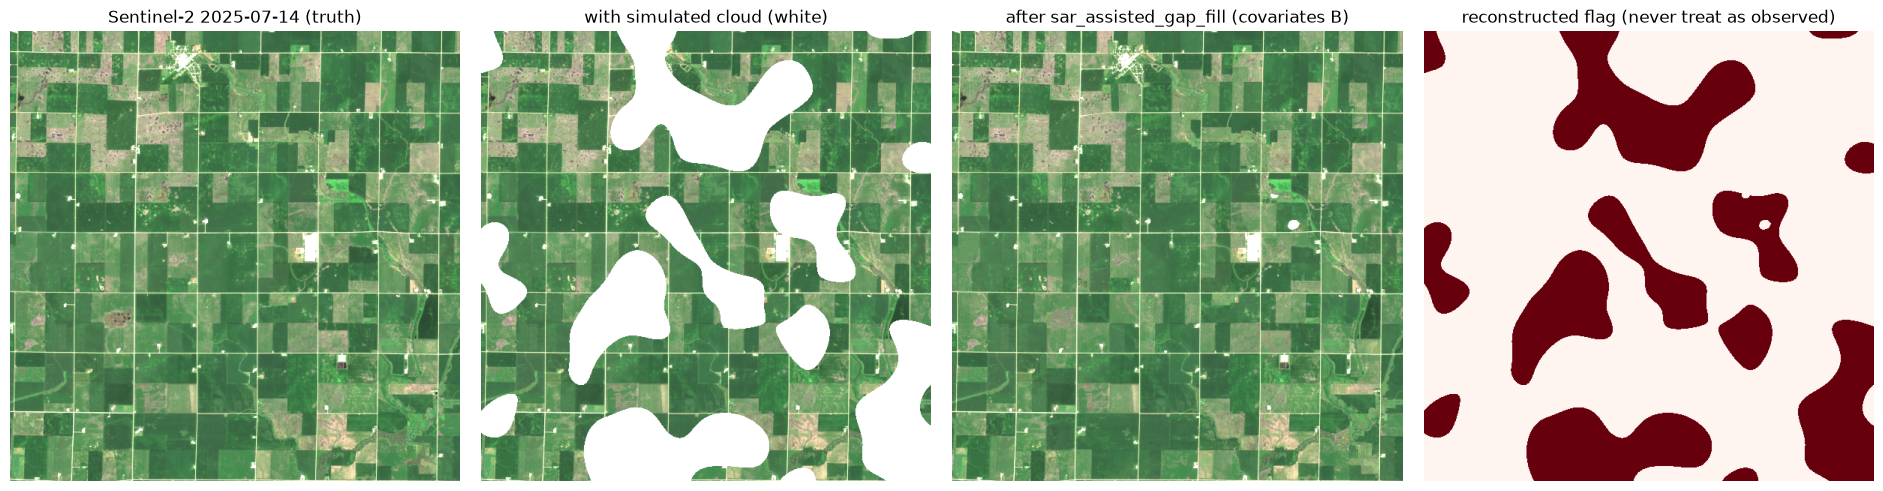

holdout R² (clear pixels)  \
A: one SAR date                      blue                          0.179   
                                     green                         0.092   
                                     red                           0.126   
                                     rededge1                      0.173   
                                     rededge2                      0.456   
                                     rededge3                      0.396   
                                     nir                           0.377   
                                     nir08                         0.387   
                                     swir16                        0.312   
                                     swir22                        0.292   
B: 6 SAR dates + June/August optical blue                          0.929   
                                     green                         0.925   
                                     red                           0.914   
                                     rededge1                      0.931   
                                     rededge2                      0.828   
                                     rededge3                      0.882   
                                     nir                           0.879   
                                     nir08                         0.876   
                                     swir16                        0.934   
                                     swir22                        0.919   

                                               R² under the cloud (vs truth)  \
A: one SAR date                      blue                              0.021   
                                     green                             0.030   
                                     red                               0.071   
                                     rededge1                          0.092   
                                     rededge2                          0.162   
                                     rededge3                          0.211   
                                     nir                               0.198   
                                     nir08                             0.207   
                                     swir16                            0.141   
                                     swir22                            0.152   
B: 6 SAR dates + June/August optical blue                              0.923   
                                     green                             0.927   
                                     red                               0.905   
                                     rededge1                          0.930   
                                     rededge2                          0.799   
                                     rededge3                          0.856   
                                     nir                               0.856   
                                     nir08                             0.859   
                                     swir16                            0.917   
                                     swir22                            0.901   

                                               RMSE under the cloud  \
A: one SAR date                      blue                     0.018   
                                     green                    0.020   
                                     red                      0.025   
                                     rededge1                 0.031   
                                     rededge2                 0.052   
                                     rededge3                 0.080   
                                     nir                      0.077   
                                     nir08                    0.078   
                                     swir16                   0.057   
                                     swir22                

In [19]:
# SAR-assisted gap filling on one image: Sentinel-2 of 14 July 2025 (20 m) with Sentinel-1 of 20 July 2025.
# We hide a realistic cloud field (smooth random blobs, ~25 % of the scene) so the truth under the "cloud" is known.
GF_S2, GF_S1 = "2025-07-14", "2025-07-20"
opt = S2C.sel(time=GF_S2).squeeze(drop=True)  # the cloud-free optical image
sar = S1C.sel(time=GF_S1).squeeze(drop=True)  # the SAR image
field = ndi.gaussian_filter(np.random.default_rng(7).random(REF.shape), 25)  # smooth random field
cloud = field > np.quantile(field, 0.75)  # its top quarter becomes "cloud"
opt_cloudy = opt.where(~xr.DataArray(cloud, dims=("y", "x")))  # the optical image with the cloud removed
opt_ds = opt_cloudy.to_dataset("band").rio.write_crs(REF.rio.crs)  # as a Dataset of bands
sar_ds = sar.to_dataset("band").rio.write_crs(REF.rio.crs)  # SAR as a Dataset
# covariates: (A) the single Sentinel-1 image of 20 July; (B) all six 2025 Sentinel-1 dates plus the two
# neighbouring clear Sentinel-2 images (22 June and 26 August). sar_assisted_gap_fill accepts any covariates.
cov = {}
for t in S1C.time.values[pd.DatetimeIndex(S1C.time.values).year == 2025]:  # the six 2025 SAR dates
    for b in ("vv", "vh"):  # VV and VH ...
        # ... as covariates
        cov[f"{b}_{pd.Timestamp(t):%m%d}"] = S1C.sel(time=t, band=b).drop_vars(["time", "band"], errors="ignore")
for t in ("2025-06-22", "2025-08-26"):  # the two neighbouring clear optical dates
    for b in BANDS:  # every band ...
        # ... as covariates
        cov[f"s2_{b}_{t[5:7]}"] = S2C.sel(time=t, band=b).squeeze(drop=True).drop_vars(["time", "band"], errors="ignore")
# two covariate sets
COVS = {"A: one SAR date": sar_ds, "B: 6 SAR dates + June/August optical": xr.Dataset(cov).rio.write_crs(REF.rio.crs)}
FILLED, rows = {}, {}  # filled images and scores
for name, cv in COVS.items():  # each covariate set
    t0 = time.time()  # start the timer
    # fill the cloud with a random forest per band
    FILLED[name], r2 = ic.sar_assisted_gap_fill(opt_ds, cv, model="rf", seed=SEED, max_train=40_000, n_estimators=100, n_jobs=-1)
    recon = FILLED[name].reconstructed.values  # pixels that were reconstructed
    for b in BANDS:  # each band
        t_, f_ = opt.sel(band=b).values[recon], FILLED[name][b].values[recon]  # truth and fill under the cloud
        ok = np.isfinite(t_) & np.isfinite(f_)  # both finite
        # hold-out R2, R2 and RMSE under the cloud
        rows[(name, b)] = {"holdout R² (clear pixels)": r2.get(b, np.nan),
                           "R² under the cloud (vs truth)": 1 - np.sum((f_[ok] - t_[ok]) ** 2) / np.sum((t_[ok] - t_[ok].mean()) ** 2),
                           "RMSE under the cloud": np.sqrt(np.mean((f_[ok] - t_[ok]) ** 2)), "reflectance SD": t_[ok].std()}
    # summary line
    print(f"{name}: {len(cv.data_vars)} covariates, {time.time() - t0:.0f} s, reconstructed {recon.mean():.1%} of the scene "
          f"(simulated cloud {cloud.mean():.1%})")
gf = pd.DataFrame(rows).T.round(3)  # the score table
filled = FILLED["B: 6 SAR dates + June/August optical"]  # the better fill
recon = filled.reconstructed.values  # its reconstructed flag

fig, ax = plt.subplots(1, 4, figsize=(19, 4.8))  # four panels
def rgb_ds(d):  # true colour of an image or Dataset
    # red, green, blue
    im = np.dstack([d[b].values if isinstance(d, xr.Dataset) else d.sel(band=b).values for b in ("red", "green", "blue")])
    return np.clip(np.nan_to_num(im, nan=1) / 0.12, 0, 1) ** 0.8  # stretch; missing shown white
zoom = (slice(300, 900), slice(300, 900))  # a 600 x 600 pixel zoom
ax[0].imshow(rgb_ds(opt)[zoom]); ax[0].set_title(f"Sentinel-2 {GF_S2} (truth)")  # the truth
ax[1].imshow(rgb_ds(opt_ds)[zoom]); ax[1].set_title("with simulated cloud (white)")  # with the cloud
# after filling
ax[2].imshow(rgb_ds(filled)[zoom]); ax[2].set_title("after sar_assisted_gap_fill (covariates B)")
# the reconstructed flag
ax[3].imshow(recon[zoom], cmap="Reds"); ax[3].set_title("reconstructed flag (never treat as observed)")
for a in ax:  # every panel
    a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw
gf  # the scores

**Reading the reconstruction.** With **one SAR date (A)** the reconstruction is poor: $R^2$ under the cloud is only 0.02 to 0.21 and the RMSE is about the standard deviation of the reflectance: the filled image is close to a blurred average. The hold-out $R^2$ reported by the function (0.09 to 0.46) is **optimistic**, because hold-out pixels are scattered among training pixels, while a cloud removes a whole contiguous area. With **multi-date SAR and the neighbouring optical dates (B)**, $R^2$ under the cloud is 0.80 to 0.93, close to the hold-out values.

### Never treat filled pixels as observed

The `reconstructed` flag must follow the pixel into every later step. Here we classify the 2025 test pixels three ways and **report the pixels under the cloud separately**.


In [20]:
# Does classification on reconstructed pixels behave like classification on observed ones?
# The 2025 test samples whose July value lies under the simulated cloud are re-classified with the July
# reflectance replaced by (a) the SAR-filled value, (b) the time-interpolated value (July dropped).
# Accuracy is always reported separately for observed and reconstructed pixels.
j25 = np.flatnonzero(d_s2 == pd.Timestamp(GF_S2))[0] - I2[2025][0]          # position of 14 Jul in the 2025 dates
under = cloud[rr, cc]  # test locations under the cloud
raw25 = X_s2[:, I2[2025]].copy()  # 2025 optical values of every location
variants = {"observed July (truth)": raw25.copy()}  # the input variants
for name, f in FILLED.items():  # each fill ...
    # ... replaces July under the cloud
    v = raw25.copy(); v[under, j25] = np.stack([f[b].values[rr, cc] for b in BANDS], 1)[under]; variants[f"July filled, covariates {name[0]}"] = v
# July dropped under the cloud
v = raw25.copy(); v[under, j25] = np.nan; variants["July dropped, interpolated in time"] = v
idx25 = te[YR[te] == 2025]  # the 2025 test samples
rows = {}  # one row per variant
for name, raw in variants.items():  # each variant
    # interpolated and normalised
    x = np.nan_to_num(NORM2.transform(interp_series(raw, DOY2[2025])[0], band_axis=2)).astype("float32")
    p = proba_seq(MODELS["TempCNN"], x, np.arange(N_LOC)).argmax(1)  # TempCNN predictions
    yt = Y[idx25]  # labels
    # accuracy under the cloud and on clear pixels
    rows[name] = {"OA, pixels under the cloud": (p[under] == yt[under]).mean(), "OA, clear pixels": (p[~under] == yt[~under]).mean(),
                  "pixels under the cloud": int(under.sum())}
pd.DataFrame(rows).T.round(3)  # show them

,"OA, pixels under the cloud","OA, clear pixels",pixels under the cloud
observed July (truth),0.916,0.905,9865.0
"July filled, covariates A",0.816,0.905,9865.0
"July filled, covariates B",0.912,0.905,9865.0
"July dropped, interpolated in time",0.881,0.905,9865.0


The clear pixels are unaffected by construction. Under the cloud, the one-date SAR fill (A) **lowers** the accuracy (0.82) below simply dropping July and interpolating in time (0.88): a bad fill is worse than an honest gap. The multi-date fill (B) restores the accuracy of the true image (0.912 vs 0.915). Had we mixed reconstructed and observed pixels in one score, or used reconstructed pixels as validation labels or inputs without a flag, the effect of the fill would have been invisible.


## Resolution: `pansharpen` and `pansharpening_quality` (Wald protocol)

Pansharpening injects the spatial detail of a high-resolution band ("pan") into lower-resolution multispectral (MS) bands. `pansharpen(ms, pan, method=)` offers **high-pass filtering** (add the pan detail $P-G_\sigma*P$, scaled), **intensity substitution** (replace the MS intensity by the histogram-matched pan) and **Brovey** (scale every band by $P/I$). The result can look sharp and still be spectrally wrong, so it must be measured against a true reference. The **Wald protocol** does this: degrade both inputs by the resolution ratio $R$, sharpen back to the original MS resolution, and compare with the original MS bands. `pansharpening_quality(fused, reference, ratio=)` reports

$$
\mathrm{ERGAS}=\frac{100}{R}\sqrt{\frac1B\sum_b\Big(\frac{\mathrm{RMSE}_b}{\mu_b}\Big)^2},\qquad
\mathrm{SAM}=\arccos\frac{\langle\mathbf f,\mathbf r\rangle}{\lVert\mathbf f\rVert\,\lVert\mathbf r\rVert}\ (\text{mean angle, degrees}),
$$

with RMSE and the mean correlation coefficient (CC). Lower ERGAS and SAM, higher CC are better. Bicubic upsampling (`super_resolution.upsample`) without pan is the baseline.

**(a) Sentinel-2:** the six 20 m bands (red edge, narrow NIR, SWIR) sharpened with a 10 m pan (the mean of blue, green, red and NIR), ratio 2, on a 10 × 10 km window of 26 August 2025.


Sentinel-2 20 m bands: (6, 512, 512) | 10 m pan: (1024, 1024)


                                             rmse    ergas  sam_deg      cc
S2 20 m -> 10 m (Wald test at 40 -> 20 m)                                  
bicubic upsampling (no pan)                0.0135   3.4908   1.0968  0.9692
highpass                                   0.0122   3.1352   1.1318  0.9756
intensity                                  0.0128   3.3817   1.1882  0.9729
brovey                                     0.1324  24.3762   1.0968  0.9273


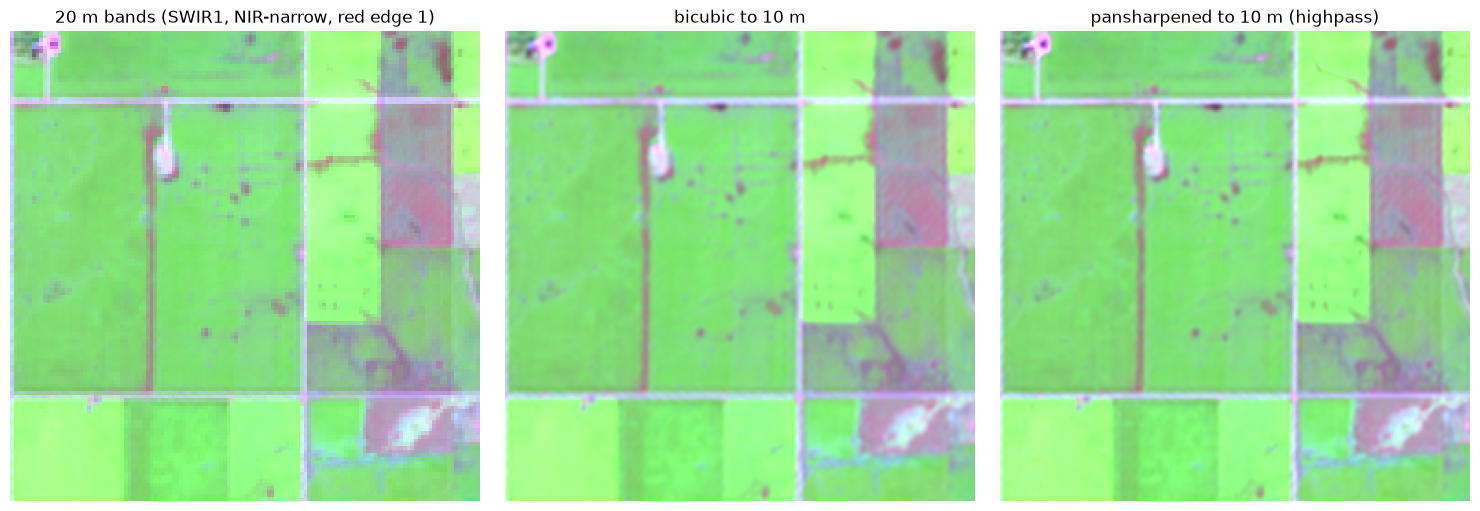

In [21]:
from geolattice.rsense.super_resolution import upsample  # bicubic upsampling helper
# Wald protocol: degrade both inputs by the resolution ratio, sharpen back to the original MS resolution,
# and compare with the original MS bands, which are then a true reference.
def block_mean(a, f):
    h, w = (a.shape[-2] // f) * f, (a.shape[-1] // f) * f  # crop to whole blocks
    a = a[..., :h, :w]  # ...
    return a.reshape(*a.shape[:-2], h // f, f, w // f, f).mean((-3, -1))  # average each f x f block

def wald(ms, pan, ratio, label):  # Wald test of pansharpening methods
    ms_lr, pan_lr = block_mean(ms, ratio), block_mean(pan, ratio)        # degraded inputs
    ref = ms[:, : ms_lr.shape[1] * ratio, : ms_lr.shape[2] * ratio]  # the original bands as reference
    rows = {}  # one row per method
    up = np.asarray(upsample(ms_lr, ratio, method="bicubic"))  # bicubic upsampling as baseline
    rows["bicubic upsampling (no pan)"] = ic.pansharpening_quality(up, ref, ratio=ratio)  # its quality
    for m in ("highpass", "intensity", "brovey"):  # three pansharpening methods
        fused = ic.pansharpen(up, pan_lr[: up.shape[1], : up.shape[2]], method=m)  # fuse
        rows[m] = ic.pansharpening_quality(fused, ref, ratio=ratio)  # quality against the reference
    out = pd.DataFrame(rows).T.round(4)  # as a table
    out.index.name = label  # label the table
    return out  # the table

# (a) Sentinel-2, 26 Aug 2025: the 20 m bands sharpened with a 10 m "pan" (mean of blue, green, red, NIR)
S2_DAY = next(p for p in S2_F if "20250826" in p.name)
# the 20 m grid starts 10 m above the 10 m grid (same left edge), so 20 m row r covers 10 m rows 2r - 1 and 2r
win10 = (slice(799, 1823), slice(800, 1824))                              # 1024 x 1024 px at 10 m (10 x 10 km)
win20 = (slice(400, 912), slice(400, 912))  # matching 20 m window
def read10(b):  # one 10 m band of the window
    # as reflectance
    return rioxarray.open_rasterio(S2_DAY / f"{b}.tif").squeeze(drop=True).values[win10].astype("float32") * 1e-4
def read20(b):  # one 20 m band of the window
    # as reflectance
    return rioxarray.open_rasterio(S2_DAY / f"{b}.tif").squeeze(drop=True).values[win20].astype("float32") * 1e-4
# the "pan": mean of the four 10 m bands
pan10 = np.mean([read10(b) for b in ("blue", "green", "red", "nir")], 0)
MS20_BANDS = ["rededge1", "rededge2", "rededge3", "nir08", "swir16", "swir22"]  # the six 20 m bands
ms20 = np.stack([read20(b) for b in MS20_BANDS])  # stacked
print("Sentinel-2 20 m bands:", ms20.shape, "| 10 m pan:", pan10.shape)  # shapes
q_s2 = wald(ms20, pan10, 2, "S2 20 m -> 10 m (Wald test at 40 -> 20 m)")  # Wald test at 40 -> 20 m
print(q_s2)  # show it

# the real product: 20 m bands sharpened to 10 m with the best method of the Wald test
best_s2 = q_s2.drop(index="bicubic upsampling (no pan)")["ergas"].idxmin()
# sharpen to 10 m with the best method
sharp10 = ic.pansharpen(np.asarray(upsample(ms20, 2, method="bicubic")), pan10, method=best_s2)
bic10 = np.asarray(upsample(ms20, 2, method="bicubic"))  # bicubic only, for comparison
# SWIR 1, NIR-narrow, red edge 1 as RGB
fc = lambda a: np.clip(np.dstack([a[MS20_BANDS.index("swir16")], a[MS20_BANDS.index("nir08")], a[MS20_BANDS.index("rededge1")]]) / np.array([0.3, 0.45, 0.15]), 0, 1)
z = (slice(300, 556), slice(300, 556))  # a zoom
fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # three panels
# the 20 m bands
ax[0].imshow(fc(ms20)[150:278, 150:278], interpolation="nearest"); ax[0].set_title("20 m bands (SWIR1, NIR-narrow, red edge 1)")
ax[1].imshow(fc(bic10)[z]); ax[1].set_title("bicubic to 10 m")  # bicubic
ax[2].imshow(fc(sharp10)[z]); ax[2].set_title(f"pansharpened to 10 m ({best_s2})")  # pansharpened
for a in ax:  # every panel
    a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

**(b) Landsat 8 with a Sentinel-2 pan:** Landsat has no panchromatic band in this download, but Sentinel-2 imaged the AOI on the same day (10 July 2023), so its 10 m bands can serve as pan for the 30 m Landsat bands (ratio 3).


In [22]:
from affine import Affine  # affine transforms
# (b) Landsat 8, 10 Jul 2023 (30 m) sharpened with the Sentinel-2 10 m pan of the same day
L8_DAY = next(p for p in L8_F if "20230710" in p.name)
S2_L = next(p for p in S2_F if "20230710" in p.name)  # Sentinel-2 of the same day
L_BANDS = ["blue", "green", "red", "nir", "swir16", "swir22"]  # the six Landsat bands
r0, c0, n10 = 799, 800, 1020                                   # 1020 x 1020 px at 10 m = 340 x 340 at 30 m
# 10 m pan from Sentinel-2
pan_l = np.mean([rioxarray.open_rasterio(S2_L / f"{b}.tif").squeeze(drop=True).values[r0:r0 + n10, c0:c0 + n10].astype("float32") * 1e-4
                 for b in ("blue", "green", "red", "nir")], 0)
ref10 = rioxarray.open_rasterio(S2_L / "red.tif").squeeze(drop=True)  # the 10 m grid
x0, y0 = float(ref10.x[c0]) - 5, float(ref10.y[r0]) + 5         # top-left corner of the 10 m window
dst = Affine(30, 0, x0, 0, -30, y0)  # the 30 m target grid aligned to it
def landsat(b):  # one Landsat band on that grid
    a = rioxarray.open_rasterio(L8_DAY / f"{b}.tif", masked=True).squeeze(drop=True)  # read with no-data masked
    a = a.rio.reproject(a.rio.crs, shape=(n10 // 3, n10 // 3), transform=dst, resampling=1)     # Landsat grid is offset by 15 m
    return (a.values.astype("float32") * 2.75e-5 - 0.2)                                           # Collection 2 surface reflectance
ms30 = np.stack([landsat(b) for b in L_BANDS])  # the six bands
# shapes and completeness
print("Landsat 30 m:", ms30.shape, "| Sentinel-2 pan 10 m:", pan_l.shape, "| finite:", np.isfinite(ms30).all())
# Wald test at 90 -> 30 m
q_l8 = wald(np.nan_to_num(ms30), pan_l, 3, "Landsat 30 m -> 10 m with S2 pan (Wald test at 90 -> 30 m)")
print(q_l8)  # show it

Landsat 30 m: (6, 340, 340) | Sentinel-2 pan 10 m: (1020, 1020) | finite: True


                                                      rmse   ergas  sam_deg  \
Landsat 30 m -> 10 m with S2 pan (Wald test at ...                            
bicubic upsampling (no pan)                         0.0132  4.9834   2.2613   
highpass                                            0.0128  4.6366   2.2847   
intensity                                           0.0137  5.6840   2.6593   
brovey                                              0.0344  6.8724   2.2613   

                                                        cc  
Landsat 30 m -> 10 m with S2 pan (Wald test at ...          
bicubic upsampling (no pan)                         0.9479  
highpass                                            0.9544  
intensity                                           0.9392  
brovey                                              0.9105  


**Reading the Wald tests.** **High-pass** filtering is the best method in both tests (ERGAS 3.49 → 3.14 for Sentinel-2, 4.98 → 4.64 for Landsat), with a small cost in SAM. **Intensity substitution** helps a little for Sentinel-2 and hurts for the cross-sensor pair. **Brovey fails badly on Sentinel-2** (ERGAS 24): it assumes the pan approximates the sum of the MS bands, but here a visible/NIR pan sharpens red-edge and SWIR bands with a different intensity, so every value is rescaled by the wrong ratio. The gains are modest because the default detail gain (0.25) is conservative, and visually the sharpened image is only slightly crisper than bicubic. For crop mapping at the 20 m scale of this notebook, pansharpening is not needed; it matters for small fields and boundaries.


## In-season mapping: accuracy against the last date available

A map is most useful **before** harvest. At the end of each month only the images acquired so far exist. For each cutoff we **remove** every later observation, re-interpolate the series (so no future image leaks into the past through interpolation), keep the grid steps up to the cutoff, retrain the models on 2020 to 2022 (early stopping on 2023) and test on 2024 to 2025.


in-season experiment: 6 cutoffs x 4 models in 7.6 min


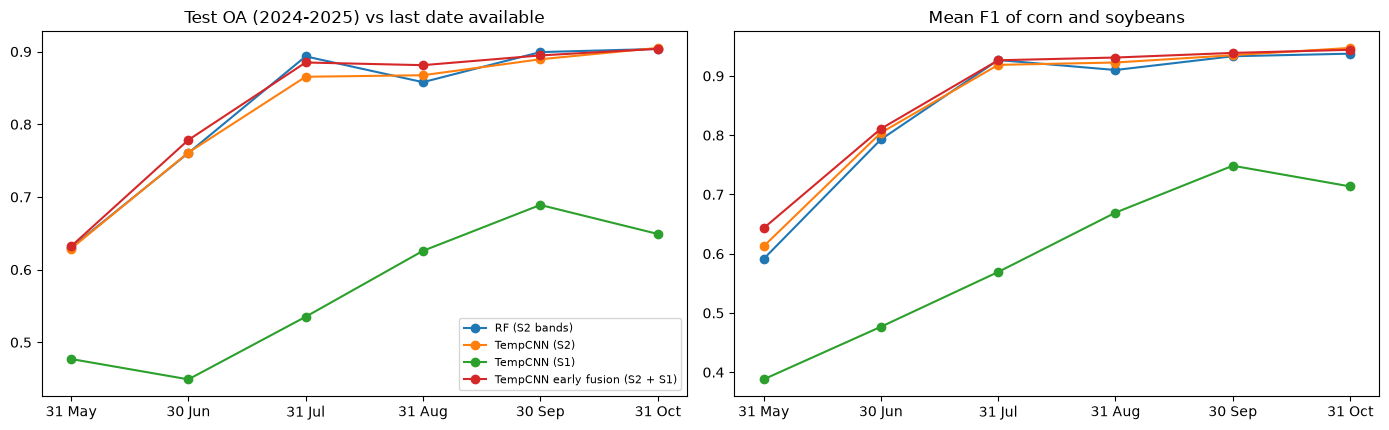

cutoff,31 May,30 Jun,31 Jul,31 Aug,30 Sep,31 Oct
model,,,,,,
RF (S2 bands),0.630,0.761,0.893,0.858,0.899,0.904
TempCNN (S1),0.477,0.449,0.535,0.626,0.689,0.649
TempCNN (S2),0.629,0.761,0.865,0.868,0.889,0.905
TempCNN early fusion (S2 + S1),0.632,0.778,0.885,0.881,0.895,0.904


In [23]:
# In-season mapping: at the end of each month only the images acquired so far exist. For each cutoff we
# re-interpolate every season from the observations up to the cutoff (later dates are removed, not just
# hidden), keep the grid steps up to the cutoff, retrain on 2020-2022 (early stopping on 2023), test on 2024-2025.
CUTOFFS = {"31 May": 151, "30 Jun": 181, "31 Jul": 212, "31 Aug": 243, "30 Sep": 273, "31 Oct": 304}
I1 = {y: np.flatnonzero(d_s1.year == y) for y in YEARS}  # SAR date indices per year
DOY1 = {y: d_s1[I1[y]].dayofyear.values for y in YEARS}  # their days of year

def series_until(cut):  # series using only dates up to the cutoff
    L = int((TGRID <= cut).sum())  # grid steps up to the cutoff
    o, s = [], []  # optical and SAR series
    for y in YEARS:  # each season
        a = X_s2[:, I2[y]].copy(); a[:, DOY2[y] > cut] = np.nan  # optical, later dates removed
        b = X_s1[:, I1[y]].copy(); b[:, DOY1[y] > cut] = np.nan  # SAR, later dates removed
        # interpolate; keep the steps up to the cutoff
        o.append(interp_series(a, DOY2[y])[0][:, :L]); s.append(interp_series(b, DOY1[y])[0][:, :L])
    o = np.nan_to_num(NORM2.transform(np.concatenate(o), band_axis=2)).astype("float32")  # normalised optical
    s = np.nan_to_num(NORM1.transform(np.concatenate(s), band_axis=2)).astype("float32")  # normalised SAR
    return o, s, L  # series and length

season_rows = []  # one row per cutoff and model
EP_S = 20 if DEVICE == "cuda" else 5  # epochs per model (fewer on a CPU)
t0 = time.time()  # start the timer
for lab, cut in CUTOFFS.items():  # each cutoff
    o, s, L = series_until(cut)  # series available at that time
    e = np.concatenate([o, s], 2)  # early-fusion input
    # random forest
    rfm = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED, min_samples_leaf=2, class_weight="balanced_subsample")
    rfm.fit(flat(o)[sub], Y[sub])  # fit on the optical bands
    preds = {"RF (S2 bands)": rfm.predict(flat(o)[te])}  # its test predictions
    # three TempCNN variants
    for name, X_, c in [("TempCNN (S2)", o, C2), ("TempCNN (S1)", s, 2), ("TempCNN early fusion (S2 + S1)", e, C2 + 2)]:
        # train it
        m, _, _ = fit_seq(ic.build_temporal_model("tempcnn", in_channels=c, num_classes=K, n_timesteps=L), X_, tr, va, epochs=EP_S)
        preds[name] = proba_seq(m, X_, te).argmax(1)  # its test predictions
    for name, p in preds.items():  # each model
        # its report
        rep = ic.classification_report(Y[te], p, labels=list(range(K)), class_names=dict(enumerate(CLASSES)))
        # the scores
        season_rows.append({"cutoff": lab, "dates on the grid": L, "model": name, "OA": rep["overall_accuracy"],
                            "macro-F1": rep["macro_f1"], "F1 corn": rep["per_class"]["f1"].iloc[0], "F1 soybeans": rep["per_class"]["f1"].iloc[1]})
season = pd.DataFrame(season_rows)  # as a table
# time taken
print(f"in-season experiment: {len(CUTOFFS)} cutoffs x 4 models in {(time.time() - t0) / 60:.1f} min")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))  # two panels
for k, g_ in season.groupby("model", sort=False):  # each model
    # accuracy and corn/soy F1 against the cutoff
    ax[0].plot(g_["cutoff"], g_["OA"], "o-", label=k); ax[1].plot(g_["cutoff"], (g_["F1 corn"] + g_["F1 soybeans"]) / 2, "o-", label=k)
# titles
ax[0].set_title("Test OA (2024-2025) vs last date available"); ax[1].set_title("Mean F1 of corn and soybeans")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()  # legend, arrange and draw
season.pivot(index="model", columns="cutoff", values="OA")[list(CUTOFFS)].round(3)  # accuracy table

**Reading the in-season curves.**

- **End of May**: about 0.63 OA. Little has emerged, and in two of the six seasons there is no clear May image at all.
- **End of June**: about 0.76 to 0.78; corn is ahead of soybeans in development.
- **End of July**: the map is essentially ready: OA 0.87 to 0.89 and a mean corn/soybean F1 of 0.92 to 0.93, about 98 % of the end-of-season value. August to October add little to corn and soybeans; they help the minor classes.
- **Early fusion** is the best model at the end of June, when SAR adds structural information before the canopy closes (at the end of May all optical models are equal, ≈ 0.63); from July on, the Random Forest on the optical bands is equal or slightly better in OA at some cutoffs, and the fused TempCNN keeps a small edge in corn/soybean F1. SAR alone stays far behind all season.


## Wall-to-wall 2025 map


The early-fusion TempCNN trained with simulated clouds (the best and most robust model of the *Optical-SAR fusion: early, middle and late, and which wins under cloud* section) classifies all 2.2 million pixels of 2025, a season it has never seen. We compare with the CDL on all labelled pixels and on the pixels the **cultivated layer** marks as cropland.


Early fusion, trained with simulated clouds: 2.2 M pixels classified in 6 s
agreement with CDL 2025: all labelled pixels 0.915, cultivated-layer pixels 0.938


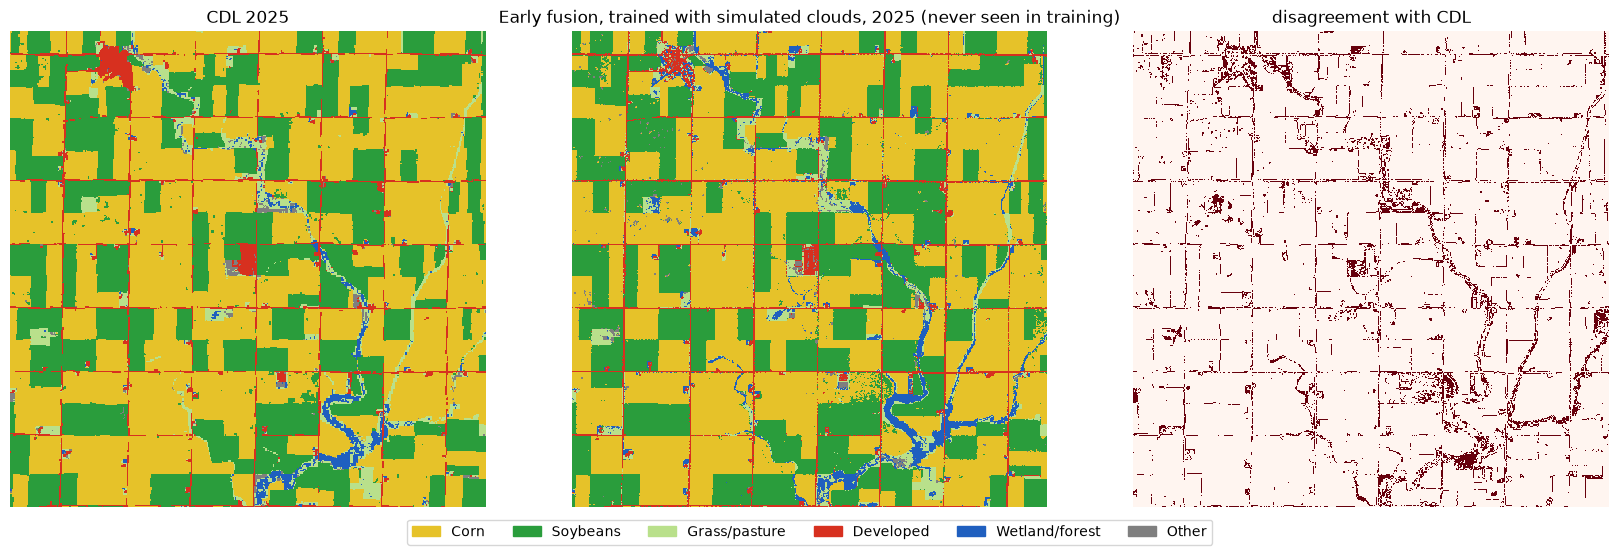

,map km²,CDL 2025 km²,difference %
Corn,444.3,462.4,-3.9
Soybeans,320.4,319.9,0.2
Grass/pasture,33.2,34.7,-4.3
Developed,42.5,39.9,6.5
Wetland/forest,30.1,13.6,121.3
Other,8.4,8.5,-1.2


In [24]:
# wall-to-wall 2025 map with the early-fusion TempCNN trained with simulated clouds (best test score and robust to cloud)
best = "Early fusion, trained with simulated clouds"
xm = np.concatenate([NORM2.transform(CUBE2[2025], band_axis=1), NORM1.transform(CUBE1[2025], band_axis=1)], 1)   # (6, 12, H, W)
# one (6, 12) series per pixel
xm = np.nan_to_num(xm.reshape(len(TGRID), C2 + 2, -1).transpose(2, 0, 1)).astype("float32")
t0 = time.time()  # start the timer
pm = proba_seq(FUS[best], xm, np.arange(len(xm))).argmax(1).reshape(REF.shape)  # classify every pixel of 2025
print(f"{best}: {pm.size / 1e6:.1f} M pixels classified in {time.time() - t0:.0f} s")  # pixels and time
ref25 = cdl[-1]  # CDL 2025
cult = LAB.cultivated.values == 2  # cultivated pixels
m_all, m_cult = ref25 >= 0, (ref25 >= 0) & cult  # labelled pixels; labelled and cultivated
# agreement on both
print(f"agreement with CDL 2025: all labelled pixels {(pm[m_all] == ref25[m_all]).mean():.3f}, "
      f"cultivated-layer pixels {(pm[m_cult] == ref25[m_cult]).mean():.3f}")
# mapped and CDL area per class (20 m pixel = 0.0004 km2)
area = pd.DataFrame({"map km²": [(pm[m_all] == k).sum() * 4e-4 for k in range(K)],
                     "CDL 2025 km²": [(ref25[m_all] == k).sum() * 4e-4 for k in range(K)]}, index=CLASSES).round(1)
# relative difference
area["difference %"] = ((area["map km²"] - area["CDL 2025 km²"]) / area["CDL 2025 km²"] * 100).round(1)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.4))  # three panels
zoom = (slice(300, 900), slice(400, 1000))  # a 600 x 600 pixel zoom
# CDL zoom
ax[0].imshow(np.where(ref25 < 0, np.nan, ref25)[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[0].set_title("CDL 2025")
# map zoom
ax[1].imshow(pm[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title(f"{best}, 2025 (never seen in training)")
err = np.where(m_all, pm != ref25, np.nan)  # disagreement
# disagreement zoom
ax[2].imshow(err[zoom], cmap="Reds", vmin=0, vmax=1, interpolation="nearest"); ax[2].set_title("disagreement with CDL")
for a in ax:  # every panel
    a.axis("off")  # no axes
# class legend
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()  # arrange and draw
pm_da = REF.copy(data=pm.astype("uint8")).rio.write_nodata(255)  # the map as a georeferenced raster
# write it as GeoTIFF
pm_da.rio.to_raster(OUT / "crop_map_2025_early_fusion_cloudaug_20m.tif", compress="deflate")
area  # area table

**Reading the map.** Agreement with the CDL is 0.915 over all pixels and 0.938 on the cultivated layer. Corn and soybean areas are within a few per cent of the CDL. The minor classes are over-predicted, especially **wetland/forest**, which receives many mixed field-edge, riparian and farmstead pixels (the class weights make the model generous to rare classes). Most disagreements are thin lines along roads, field edges and streams, where 20 m pixels mix classes, and the small town in the north, which the map breaks up into soybeans, wetland/forest and developed.


## Summary of the experiments


In [25]:
# headline scores of every pixel model
summary = pd.DataFrame(RESULTS).T[["OA", "kappa", "macro-F1", "OA 2024", "OA 2025", "F1 corn", "F1 soybeans"]].astype(float).round(3)
# header
print("Pixel classifiers, temporal split (train 2020-2022, model selection 2023, test 2024-2025, cloud-free):")
print(summary.sort_values("macro-F1", ascending=False))  # sorted by macro F1
print("\nDense patch models (pixel scores on the 2024-2025 test patches):")  # header
print(pd.DataFrame(DENSE).T[["pixel OA", "macro-F1", "mIoU"]].astype(float).round(3))  # dense model scores
# save the result tables
summary.to_csv(OUT / "test_scores_pixel_models.csv"); clouds.to_csv(OUT / "cloud_experiment.csv"); season.to_csv(OUT / "in_season.csv")

Pixel classifiers, temporal split (train 2020-2022, model selection 2023, test 2024-2025, cloud-free):
                                                      OA  kappa  macro-F1  \
Early fusion, trained with simulated clouds        0.915  0.858     0.708   
Late fusion, weight x share of optical dates seen  0.912  0.853     0.708   
Late fusion (fuse_late)                            0.912  0.853     0.708   
LSTM (S2)                                          0.907  0.845     0.702   
TempCNN (S2)                                       0.905  0.843     0.698   
RF, raw bands x dates (S2)                         0.904  0.839     0.686   
Early fusion (TempCNN)                             0.901  0.835     0.672   
RF, phenology features (S2)                        0.874  0.790     0.667   
L-TAE (S2)                                         0.879  0.799     0.660   
Middle fusion (two-branch CNN, 7 x 7 chips)        0.899  0.833     0.656   
SAR only (TempCNN)                                

## Interpretation, caveats and recommended recipe

**What the numbers say** (40 000 locations × 6 seasons; train 2020 to 2022, model selection 2023, test 2024 to 2025):

* **Evaluate on unseen seasons.** A random split of pixel-years overstates OA by about 3 points and macro-F1 by about 7 points, mostly because test pixels share their season with training pixels.
* **Corn and soybeans are separable from the season's shape.** All good models reach OA 0.90 to 0.92 and corn/soybean F1 ≈ 0.95 on unseen seasons; the minor classes (grass, developed, wetland/forest, other) keep macro-F1 near 0.70.
* **Model complexity matters less than data and evaluation.** TempCNN, LSTM, ConvLSTM, a raw-band Random Forest and the fusion models are within about 0.01 to 0.02 OA of each other. Phenology metrics on a monthly grid and L-TAE are a step behind. PSE-TAE and U-TAE, the state of the art on dense benchmarks, do not win with six dates and 1 700 parcels.
* **Fusion pays off under cloud, but only if the model expects missing data.** In clear conditions optical alone is enough. Under simulated cloud, early fusion trained with simulated clouds and availability-weighted late fusion degrade gracefully to the SAR level, while clean-trained fusion collapses below SAR alone.
* **Gap filling needs the right covariates and must stay flagged.** One SAR date cannot reconstruct reflectance (R² ≈ 0.02 to 0.21 under the cloud) and makes the classification worse than an honest gap. Multi-date SAR plus neighbouring optical dates reconstructs it well (R² 0.80 to 0.93).
* **The crop map is ready by the end of July** (mean corn/soybean F1 ≈ 0.92 to 0.93, about 98 % of the end-of-season value).
* **High-pass pansharpening** is the only method that improves both Sentinel-2 and cross-sensor Landsat sharpening in the Wald test; Brovey must not be used with a pan that does not match the MS bands spectrally.

**Caveats**

* **CDL is the reference**, with its own errors (minor classes in particular). Scores measure agreement with CDL, not ground truth.
* **One clear image per month.** The archive was screened for clear images, so clouds were simulated; real clouds are spatially and temporally correlated, and real cloud shadows and haze are not fully masked by the SCL.
* **Missing months are held, not invented.** Where a season has no May image, the May value is the June value; this lowers early-season accuracy in those years.
* **Parcels are proxies** built from the CDL itself, so parcel labels are pure by construction.
* **One AOI** (about 30 × 30 km in Iowa) and six seasons; spatial transfer to other regions is not tested. Single runs (one seed per model).

**Recommended recipe**

1. Build one cube per sensor on a common grid; keep the cloud mask, and record for every interpolated value how far it is from a real observation.
2. Split by season with `temporal_split` (and, if the map must transfer in space, by spatial block as well).
3. Start with a Random Forest on the raw band values of a regular time grid; then a TempCNN or LSTM on the same series.
4. Use early fusion with SAR **trained with simulated cloud loss** (or availability-weighted late fusion) whenever the optical series will be incomplete.
5. Fill gaps only with multi-temporal covariates, keep the `reconstructed` flag, and never validate on reconstructed pixels.
6. For in-season maps, remove future images before interpolating; expect a reliable corn/soybean map by the end of July in this region.
7. Validate any sharpening with the Wald protocol before using it.

### References
- Pelletier, C., Webb, G. I., & Petitjean, F. (2019). Temporal convolutional neural network for the classification of satellite image time series. *Remote Sensing*, 11(5), 523.
- Garnot, V. S. F., & Landrieu, L. (2020). Lightweight temporal self-attention for classifying satellite images time series. *AALTD, ECML-PKDD Workshop*.
- Garnot, V. S. F., Landrieu, L., Giordano, S., & Chehata, N. (2020). Satellite image time series classification with pixel-set encoders and temporal self-attention. *CVPR*.
- Garnot, V. S. F., & Landrieu, L. (2021). Panoptic segmentation of satellite image time series with convolutional temporal attention networks. *ICCV*.
- Shi, X., Chen, Z., Wang, H., Yeung, D.-Y., Wong, W.-K., & Woo, W.-C. (2015). Convolutional LSTM network: a machine learning approach for precipitation nowcasting. *NeurIPS*.
- Jönsson, P., & Eklundh, L. (2004). TIMESAT: a program for analyzing time-series of satellite sensor data. *Computers & Geosciences*, 30(8), 833-845.
- Wald, L., Ranchin, T., & Mangolini, M. (1997). Fusion of satellite images of different spatial resolutions: assessing the quality of resulting images. *Photogrammetric Engineering and Remote Sensing*, 63(6), 691-699.
- Boryan, C., Yang, Z., Mueller, R., & Craig, M. (2011). Monitoring US agriculture: the US Department of Agriculture, National Agricultural Statistics Service, Cropland Data Layer program. *Geocarto International*, 26(5), 341-358.
